# Variogram analysis, kriging and simulation of a node attribute


In this notebook, variogram analysis, kriging and simulation (Sequential Gaussian Simulation, SGS) of a node attribute are illustrated. Two main strategies are proposed. The main sections of the notebooks are the following:

1. Load a karst network and set a node property
2. Prepare the example for reconstruction (removing value at some nodes)
3. Reconstruction of missing data - strategy I
    - do a variogram analysis on the entire graph and fit a covariance model
    - krige / simulate
4. Reconstruction of missing data - strategy II (two steps procedure)
    - estimate a target mean value of the considered property over each branch of the original graph (using kriging on the graph of branches)
    - do a variogram analysis intra-branch (considering pair of nodes within a same branch) on the original graph and fit a covariance model
    - krige / simulate missing values on the original graph node, while restraining the neighborhood to the branch containing the estimated / simulated node, based on simple kriging with mean at nodes set to the target mean

In [1]:
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
import scipy
import pandas as pd
import time


In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
import pyvista as pv

# Choose backend for pyvista with jupyter
# ---------------------------------------
pv.set_jupyter_backend('static') # static plots
# pv.set_jupyter_backend('trame')  # 3D-interactive plots

# Notes:
# -> ignored if run in a standard python shell
# -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.6


## 1. Prepare karst network and set a node property

## Load karst network
Load karst network from yaml or csv files.

In [5]:
# # From csv files
# basename = '../data/047_Seefeldhoele_000/clean_graph_csv/047_Seefeldhoele_000'
# kg = kn.from_csv(
#         basename,
#         suffix_nodes='_node_pos.csv', 
#         suffix_edges='_edges.csv', 
#         delimiter_nodes=';',  
#         delimiter_edges=';',
#         import_node_scalar_properties=True,
#         import_edge_scalar_properties=True,
#         verbose=True)

# From yaml file
filename = '../data/047_Seefeldhoele_000/047_Seefeldhoele_000.yaml'
kg = kn.from_yaml(filename)


This network contains 1 connected components
   This network contains 1 looping branch.es. 
   Tortuosity is infinite on a looping branch. 
   The looping branches are not considered for the mean tortuosity computation.

Karstnet graph successfully created from yaml file !



## Check original graph and graph of branches


In [6]:
G = kg.graph
print('\nOriginal graph - list of node attributes:\n  ', kn.utils.get_node_attribute_names(G))
print('\nOriginal graph - list of edge attributes:\n  ', kn.utils.get_edge_attribute_names(G))


Original graph - list of node attributes:
   ['comments', 'pos', 'branch_ids_list', 'flags', 'csdim', 'splays', 'idsql', 'fulladdress']

Original graph - list of edge attributes:
   ['azimuth', 'length2d', 'flags', 'dip', 'length']


In [7]:
Gb = kg.graph_of_branches
print('\nGraph of branches - list of node attributes:\n  ', kn.utils.get_node_attribute_names(Gb))
print('\nGraph of branches - list of edge attributes:\n  ', kn.utils.get_edge_attribute_names(Gb))


Graph of branches - list of node attributes:
   ['length', 'pos']

Graph of branches - list of edge attributes:
   []


## Compute diameter from cross-section width and height on graph nodes
Compute the diameter as the geometric mean of the cross-section width and cross-section height (attribute 'csdim', list of 2 values). Set the diameter and log10 of diameter as node attributes on the original graph.


In [8]:
# Get cross-section width and height (list of 2 values)
csdim = nx.get_node_attributes(G, 'csdim', default=[np.nan, np.nan])

# Compute diameter and replace 0 by nan
diameter = {u: float(np.sqrt(csdim[u][0]*csdim[u][1])) for u in G.nodes()}
for u in G.nodes():
    if np.isclose(diameter[u], 0.0):
        diameter[u] = np.nan

# Compute log10 of diameter
log10_diameter = {u: float(np.log10(diameter[u])) for u in G.nodes()}

# Set nodes attribute
nx.set_node_attributes(G, diameter, 'diameter')
nx.set_node_attributes(G, log10_diameter, 'log10_diameter')

## Plot graphs with node attribute

### Plot in 2D (projection)

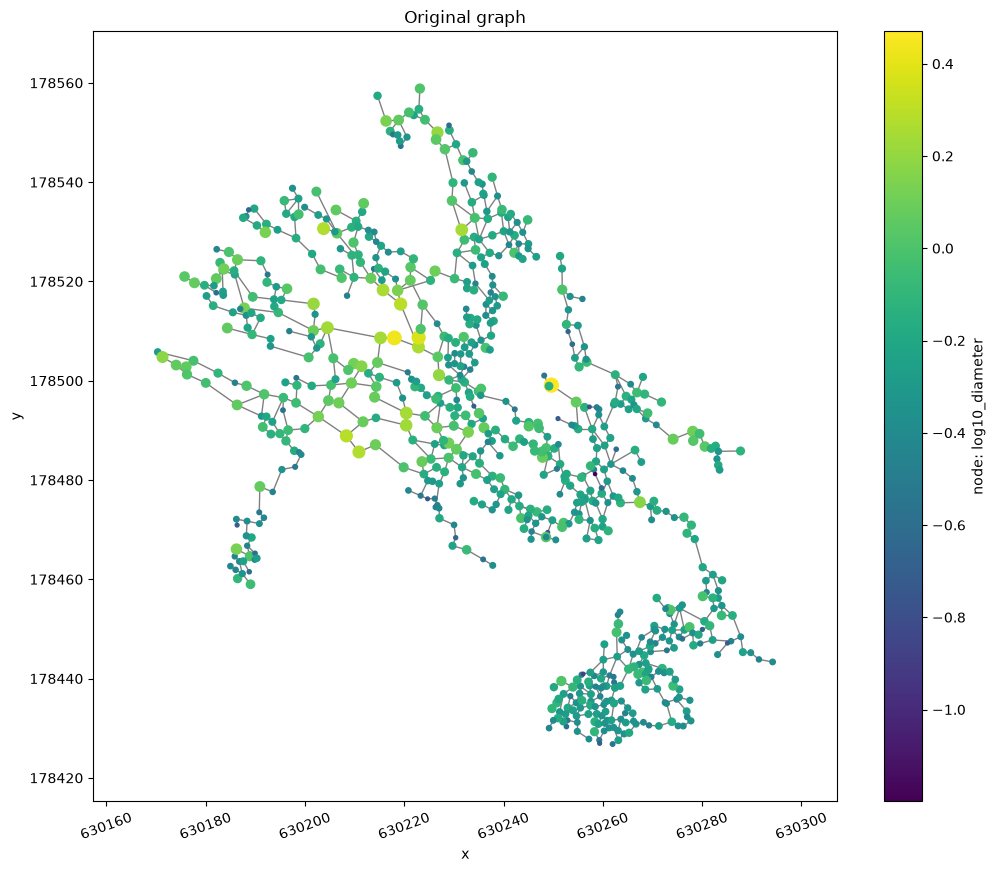

In [9]:
# Original graph
# --------------

# Attribute to be plotted
node_attr = 'log10_diameter'

# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 5
size_max = 100
size_nan = 1
exponent = 3
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options = {
    'node_size'   : node_size,  # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}

plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    G,
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title('Original graph')
plt.axis('equal')
plt.show(block=True)


### Plot in 3D

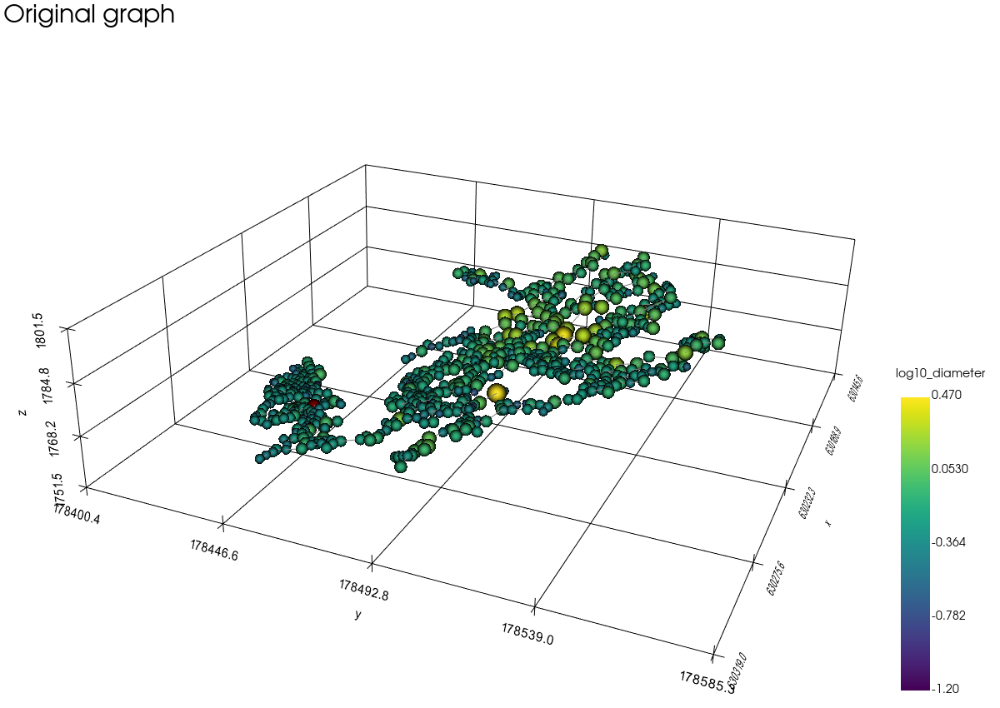

In [10]:
# Original graph
# --------------

# Attribute to be plotted
node_attr = 'log10_diameter'

# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold')       # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red', alpha=1.0) # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 1
size_max = 3
size_nan = 2
exponent = 2
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options_nodes = {
    'point_size' : node_size,  # node size
    'cmap'       : cmap,       # node color map
    #'vmin':-1.2
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=(1200, 850), notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':node_attr+'\n', 'title_font_size':14, 'label_font_size':14, 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text('Original graph', font_size=12)

cpos = pp.show(cpos=cpos, return_cpos=True)


## 2. Preparation for reconstruction example
Remove randomly the value of 'log10_diameter' attribute at some nodes. Then the goal will be to krige / simulate (Sequential Gaussian Simulation, SGS) the missing values.

## Remove the node property at some nodes


In [12]:
node_attr = 'log10_diameter'

# Get dictionary of the node attributes
node_attr_dict = nx.get_node_attributes(G, node_attr, default=np.nan)
node_attr_dict_save = node_attr_dict.copy()  # save the original node attributes

# Remove 35% of the values (randomly)
np.random.seed(4322)  # for reproducibility
num_to_remove = int(0.35 * len(node_attr_dict))
nodes_to_remove = np.random.choice(list(node_attr_dict.keys()), size=num_to_remove, replace=False)
for node in nodes_to_remove:
    node_attr_dict[node] = np.nan

# Set the node attributes (with missing values) back to the graph
nx.set_node_attributes(G, node_attr_dict, node_attr)

# List of nodes with missing values
nodes_with_missing_values = [u for u, v in node_attr_dict.items() if np.isnan(v)]

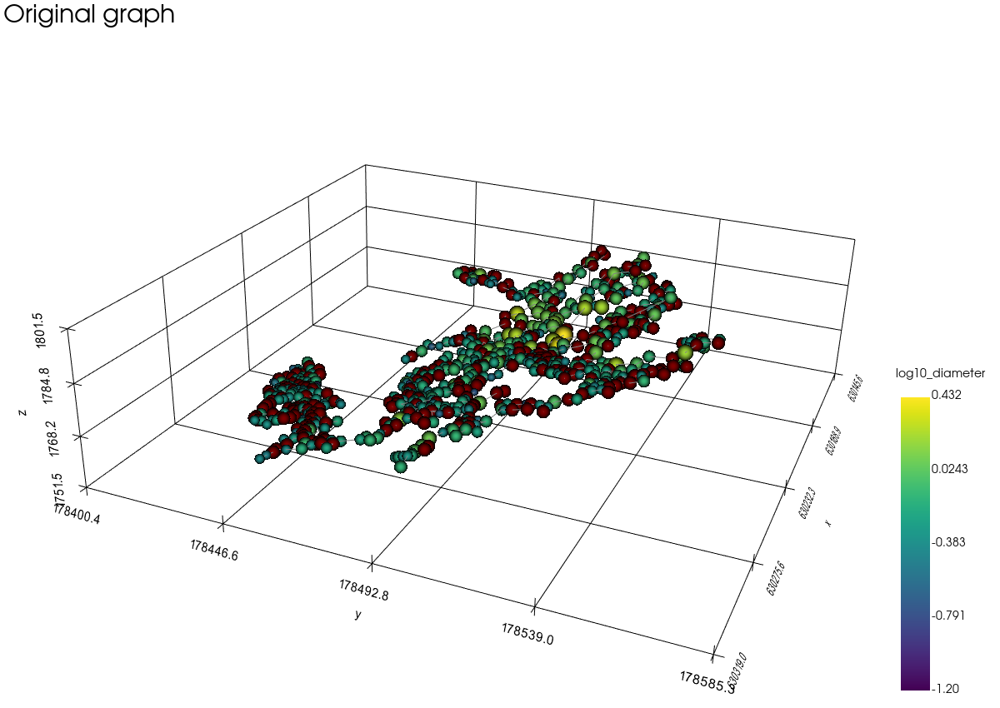

In [13]:
# Original graph
# --------------

# Attribute to be plotted
node_attr = 'log10_diameter'

# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold')       # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red', alpha=1.0) # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 1
size_max = 3
size_nan = 2
exponent = 2
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options_nodes = {
    'point_size' : node_size,  # node size
    'cmap'       : cmap,       # node color map
    #'vmin':-1.2
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=(1200, 850), notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':node_attr+'\n', 'title_font_size':14, 'label_font_size':14, 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text('Original graph', font_size=12)

cpos = pp.show(cpos=cpos, return_cpos=True)


## Basic statistics

In [14]:
# Get array of values
node_attr = 'log10_diameter'

node_attr_dict = nx.get_node_attributes(G, node_attr, default=np.nan)
node_attr_array = np.asarray(list(node_attr_dict.values()))

attr_mean = np.nanmean(node_attr_array)
attr_var = np.nanvar(node_attr_array)
print(f'Attribute "{node_attr}"')
print(f'   Number of defined values: {np.sum(np.isfinite(node_attr_array))} over {len(node_attr_array)}')
print(f'   Mean    : {attr_mean:.4f}')
print(f'   Variance: {attr_var:.4f}')


Attribute "log10_diameter"
   Number of defined values: 487 over 748
   Mean    : -0.2240
   Variance: 0.0360


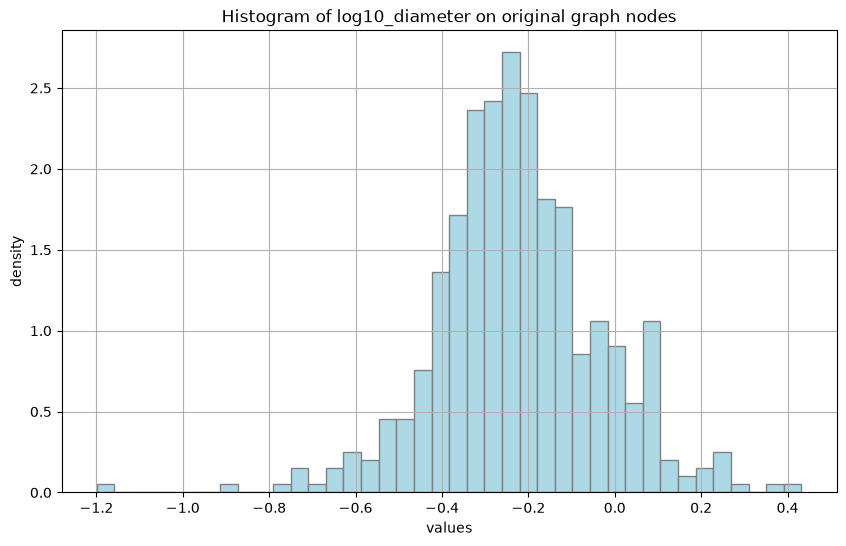

In [15]:
# Histogram
plt.figure(figsize=(10, 6))
plt.hist(node_attr_array, density=True, bins=40, color='lightblue', edgecolor='gray')
plt.xlabel('values')
plt.ylabel('density')
plt.title('Histogram of ' + node_attr + ' on original graph nodes')
plt.grid()
plt.show()

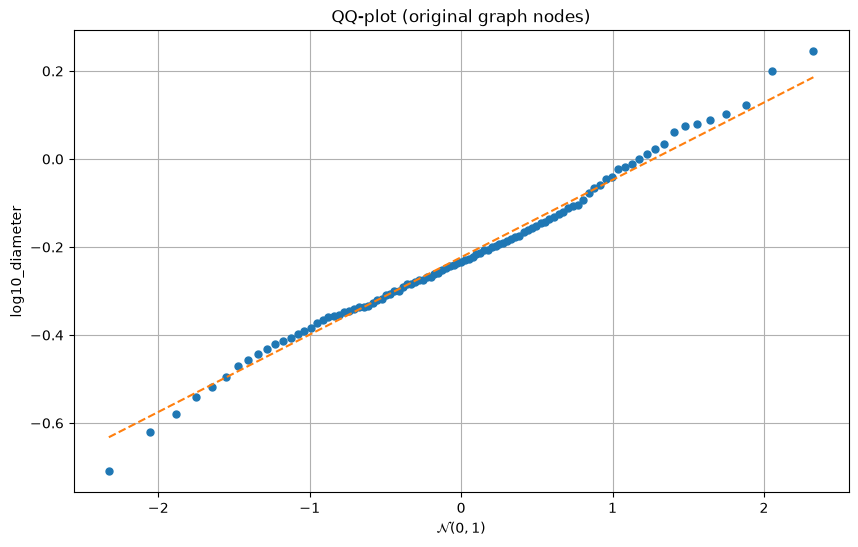

In [16]:
# QQ-plot VS N(0, 1)
 
q = 0.01 + np.arange(99)*0.01

x = scipy.stats.norm.ppf(q)
y = np.quantile(node_attr_array[~np.isnan(node_attr_array)], q=q)

y_mean = np.nanmean(y)
y_std = np.nanstd(y)
x_line = np.array([x.min(), x.max()])
y_line = y_mean + y_std * x_line

plt.figure(figsize=(10, 6))
plt.plot(x, y,  ls='', marker='o', markersize=5, color='tab:blue')
plt.plot(x_line, y_line, ls='--', color='tab:orange', label='y = mean + std * x')
plt.xlabel(r'$\mathcal{N}(0, 1)$')
plt.ylabel(node_attr)
plt.title('QQ-plot (original graph nodes)')
plt.grid()
plt.show()

## 3. Reconstruction of missing data (I)

The strategy:
- do a variogram analysis over the entire graph and fit a covariance model
- krige / simulate missing values on graph nodes


## 3.1 Variogram analysis over the entire original graph

The methods `variogram_cloud` and `variogram_exp` of a `KGraph` object allow to compute for a given node property respectively the variogram cloud and the experimental variogram; any pair of points is considered, accounting for the real shortest path length (sum of the lengths of the edges between the two points along the shortest path).

*Note: the functions `kn.tools.variogram_cloud` and `kn.tools.variogram_exp_from_variogram_cloud` can also be used.*

In [17]:
node_attr = 'log10_diameter'
hmax = 100                 # maximal distance for pair of nodes

ncla = 30                  # number of classes for variogram experimental computation
nsample_start_nodes = 5000 # number of starting node (inducing pairs) to sample for variogram cloud computation
seed = 9824                # random seed for reproducibility

### Experimental variogram

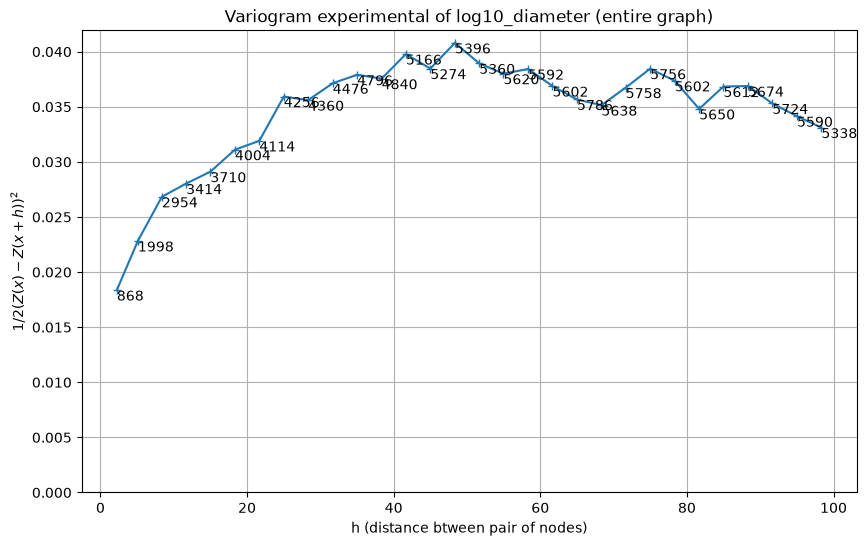

In [18]:
# Variogram experimental
plt.figure(figsize=(10, 6))

# Using method of KGraph object
hexp, gexp, nexp = kg.variogram_exp(
                        node_attr=node_attr,
                        nsample_start_nodes=nsample_start_nodes,
                        hmax=hmax,
                        ncla=ncla, 
                        seed=seed,
                        make_plot=True,
                        show_count=True,
                        color='tab:blue')

plt.grid()
plt.title('Variogram experimental of ' + node_attr + ' (entire graph)')
plt.show()

### Or : Variogram cloud, then experimental variogram

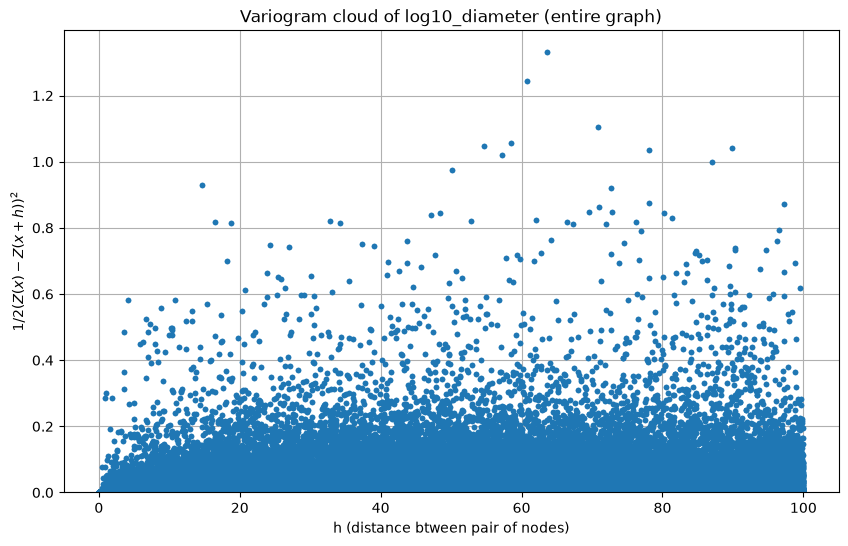

In [19]:
# Variogram cloud
plt.figure(figsize=(10, 6))

# Using method of KGraph object
h, gamma, npair = kg.variogram_cloud(
                                node_attr=node_attr,
                                nsample_start_nodes=nsample_start_nodes,
                                hmax=hmax, 
                                seed=seed,
                                make_plot=True,
                                verbose=0)

# # OR: Using function applied to NetworkX graph
# h, gamma, npair = kn.tools.variogram_cloud(
#                                 G, 
#                                 node_attr=node_attr,
#                                 edge_length_attr='length', 
#                                 nsample_start_nodes=nsample_start_nodes,
#                                 hmax=hmax, 
#                                 seed=seed,
#                                 make_plot=True,
#                                 verbose=0)
plt.grid()
plt.title('Variogram cloud of ' + node_attr + ' (entire graph)')
plt.show()

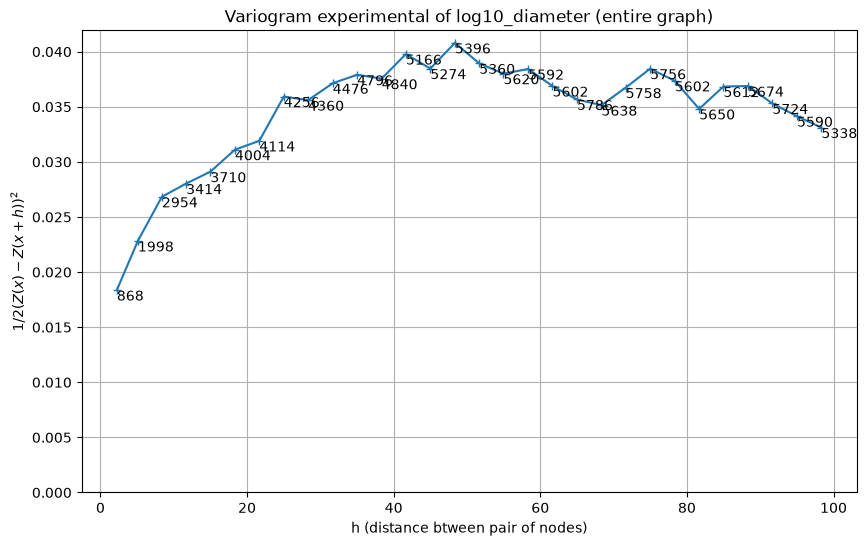

In [20]:
# Variogram experimental - using pre-computed variogram cloud
plt.figure(figsize=(10, 6))

# Using method of KGraph object - using variogram cloud computed above
hexp, gexp, nexp = kg.variogram_exp(
                        variogramCloud=(h, gamma, npair),
                        ncla=ncla,
                        hmax=hmax,
                        make_plot=True,
                        show_count=True,
                        color='tab:blue')

# # OR: Using function applied to NetworkX graph - using variogram cloud computed above
# hexp, gexp, nexp = kn.tools.variogram_exp_from_variogram_cloud(
#                         variogramCloud=(h, gamma, npair),
#                         ncla=ncla,
#                         hmax=hmax,
#                         make_plot=True,
#                         show_count=True,
#                         color='tab:blue')

plt.grid()
plt.title('Variogram experimental of ' + node_attr + ' (entire graph)')
plt.show()

### Fit a covariance model / variogram model
A covariance model is a function $C(h)$ of one argument (the distance between two nodes). The corresponding variogram model is the function $C(0) - C(h)$.

Several classic covariance model are available in `kn.tools`.

In [21]:
# Example with two structures

def cov_model(h):
    # return kn.tools.cov_sph(h, w=attr_var, r=180.)
    return kn.tools.cov_exp(h, w=0.6*attr_var, r=35.) \
           + kn.tools.cov_sph(h, w=0.4*attr_var, r=2.)


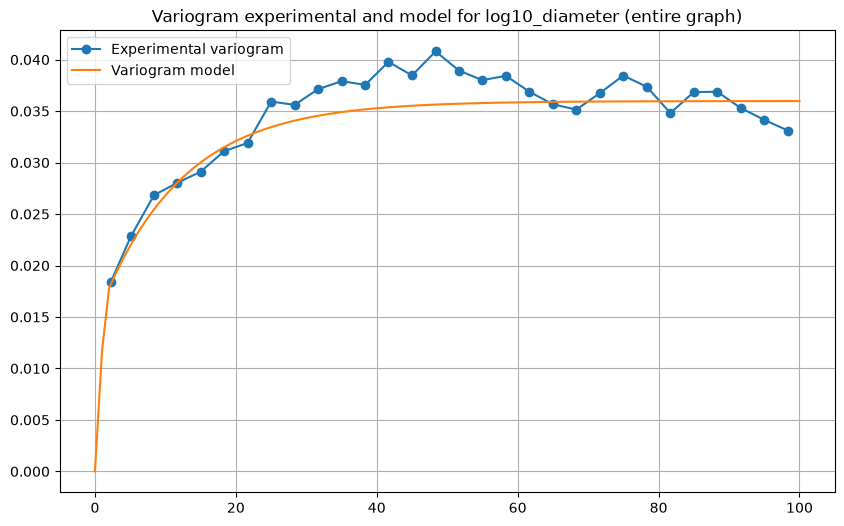

In [22]:
h = np.linspace(0, hmax, 100)
vario_model_h = cov_model(0) - cov_model(h)

plt.figure(figsize=(10, 6))

plt.plot(hexp, gexp, 'o-', label='Experimental variogram')
plt.plot(h, vario_model_h, '-', label='Variogram model')

plt.grid()
plt.legend()
plt.title('Variogram experimental and model for ' + node_attr + ' (entire graph)')
plt.show()

## 3.2. Kriging and simulation (SGS)


### Kriging

The function `kn.tools.krige_node_attribute[_mp]` do kriging on the nodes of a graph. 

*Note: `kn.tools.krige_node_attribute` is serial and `kn.tools.krige_node_attribute_mp` use multiprocessing.*

In [23]:
# Kriging - parallel

# Attribute to be kriged
node_attr = 'log10_diameter'

# Parameters
# ----------
# Kriging type
# method = 'ordinary_kriging'
method = 'simple_kriging' 
# Note : with simple krging, if the mean is not specified, it is set to the mean of the known values of the node attribute

# Neighborhood parameters
use_unique_neighborhood = False # if True all nodes are taken into account for kriging (no neighborhood search)
nneighborMax = 12      # Maximal number of neighbors (if use_unique_neighborhood=False)
searchRadius = 200.0   # Maximal distance to search for neighbors (if use_unique_neighborhood=False)

nproc = 4 # number of processes (multiprocessing)

# Node attributes for results of kriging
node_attr_krig_est = node_attr + '_krig_est' # kriging estimate
node_attr_krig_std = node_attr + '_krig_std' # kriging standard deviation

t1 = time.time()
krig_est, krig_std = kn.tools.krige_node_attribute_mp(
        G,         # Graph
        cov_model, # covariance model used (function)
        node_attr, # Node attribute to be kriged
        edge_length_attr='length', # Edge attribute used for distance computation
        method=method,
        use_unique_neighborhood=use_unique_neighborhood,
        nneighborMax=nneighborMax,
        searchRadius=searchRadius,
        update_graph=True, # if True, add two new node attributes in the graph (kriging estimate and std)
        kriging_est_node_attr=node_attr_krig_est,
        kriging_std_node_attr=node_attr_krig_std,
        nproc=nproc,
        verbose=1)
t2 = time.time()
print(f'Kriging ({nproc} processes) - Elapsed time: {t2-t1:.3g} sec')

Running `krige_node_attribute` on 4 processes...
[pid=0] Kriging:   1%
[pid=0] Kriging:   2%
[pid=0] Kriging:   3%
[pid=0] Kriging:   4%
[pid=0] Kriging:   5%
[pid=0] Kriging:   6%
[pid=0] Kriging:   7%
[pid=0] Kriging:   8%
[pid=0] Kriging:   9%
[pid=0] Kriging:  10%
[pid=0] Kriging:  11%
[pid=0] Kriging:  12%
[pid=0] Kriging:  13%
[pid=0] Kriging:  14%
[pid=0] Kriging:  15%
[pid=0] Kriging:  16%
[pid=0] Kriging:  17%
[pid=0] Kriging:  18%
[pid=0] Kriging:  19%
[pid=0] Kriging:  20%
[pid=0] Kriging:  21%
[pid=0] Kriging:  22%
[pid=0] Kriging:  23%
[pid=0] Kriging:  24%
[pid=0] Kriging:  25%
[pid=0] Kriging:  26%
[pid=0] Kriging:  27%
[pid=0] Kriging:  28%
[pid=0] Kriging:  29%
[pid=0] Kriging:  30%
[pid=0] Kriging:  31%
[pid=0] Kriging:  32%
[pid=0] Kriging:  33%
[pid=0] Kriging:  34%
[pid=0] Kriging:  35%
[pid=0] Kriging:  36%
[pid=0] Kriging:  37%
[pid=0] Kriging:  38%
[pid=0] Kriging:  39%
[pid=0] Kriging:  40%
[pid=0] Kriging:  41%
[pid=0] Kriging:  42%
[pid=0] Kriging:  43%
[pid=

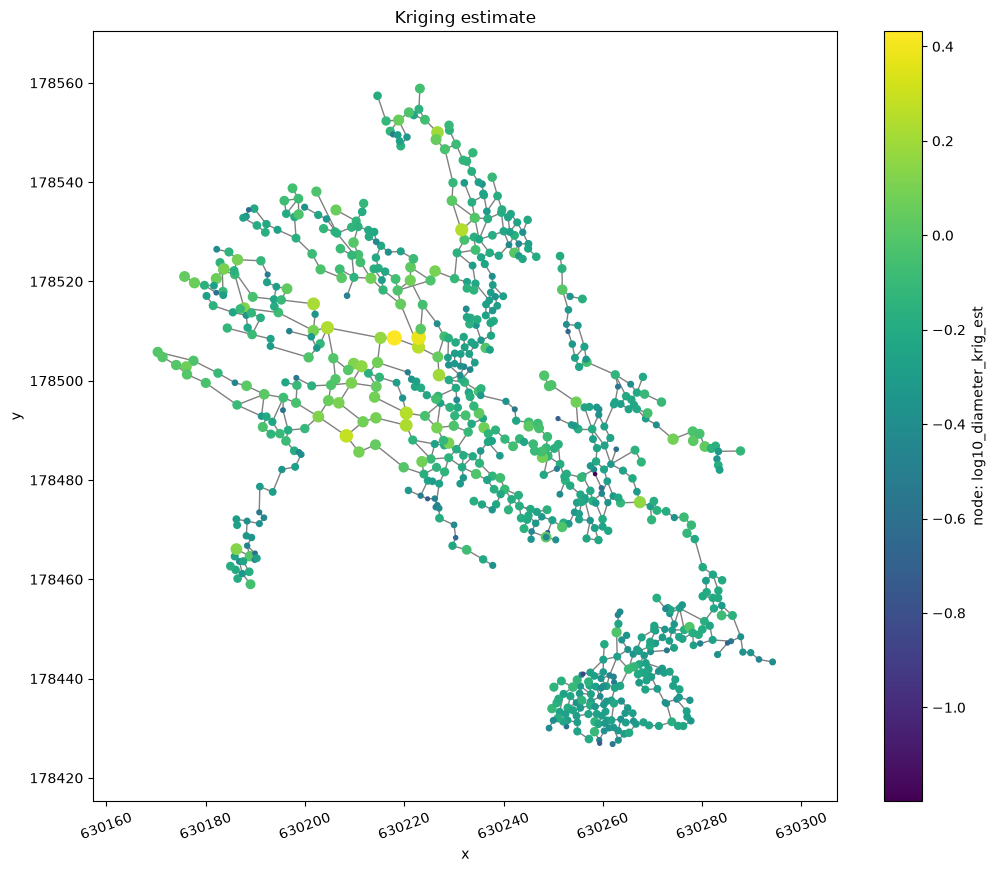

In [24]:
# Original graph
# --------------

# Attribute to be plotted
node_attr = node_attr_krig_est

# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 5
size_max = 100
size_nan = 1
exponent = 3
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options = {
    'node_size'   : node_size,  # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}

plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    G,
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title('Kriging estimate')
plt.axis('equal')
plt.show(block=True)


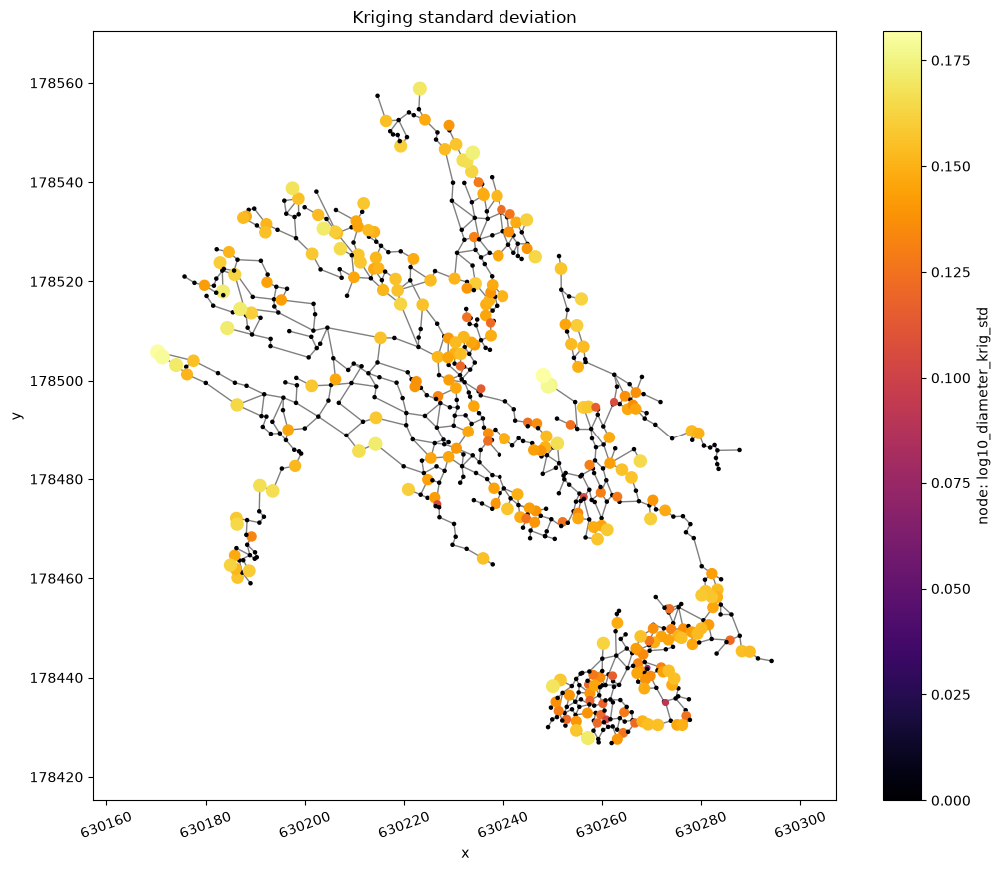

In [25]:
# Original graph
# --------------

# Attribute to be plotted
node_attr = node_attr_krig_std

# Color map for node attribute
cmap = plt.get_cmap('inferno')
# cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
# cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
# cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 5
size_max = 100
size_nan = 1
exponent = 3
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options = {
    'node_size'   : node_size,  # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}

plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    G,
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title('Kriging standard deviation')
plt.axis('equal')
plt.show(block=True)


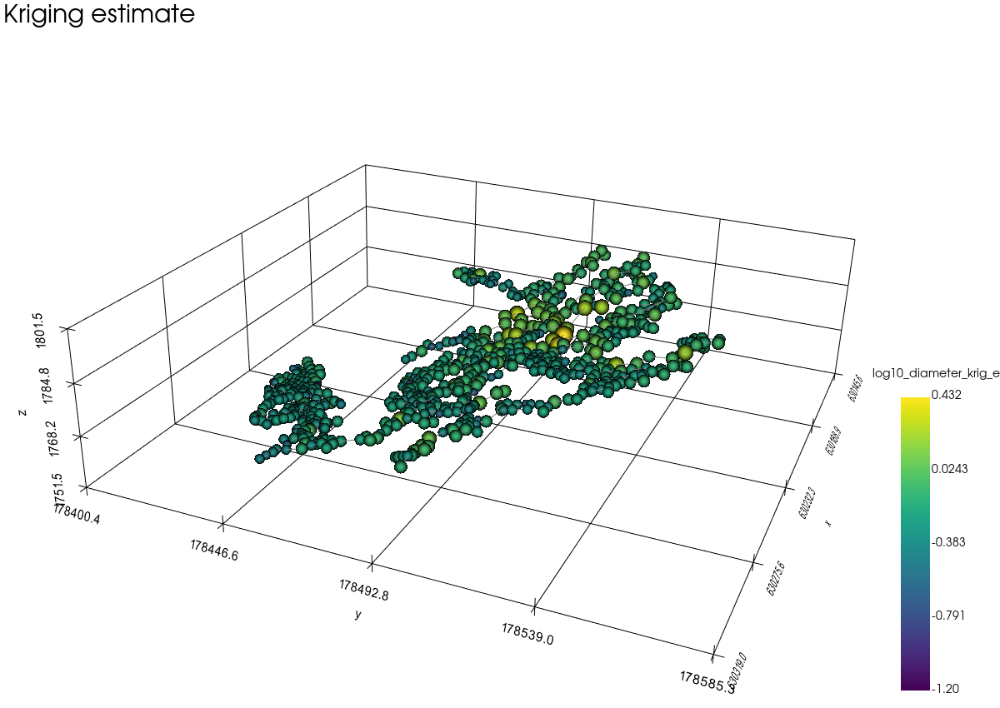

In [26]:
# Original graph
# --------------

# Attribute to be plotted
node_attr = node_attr_krig_est

# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold')       # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red', alpha=1.0) # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 1
size_max = 3
size_nan = 2
exponent = 2
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options_nodes = {
    'point_size' : node_size,  # node size
    'cmap'       : cmap,       # node color map
    #'vmin':-1.2
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=(1200, 850), notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':node_attr+'\n', 'title_font_size':14, 'label_font_size':14, 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text('Kriging estimate', font_size=12)

cpos = pp.show(cpos=cpos, return_cpos=True)


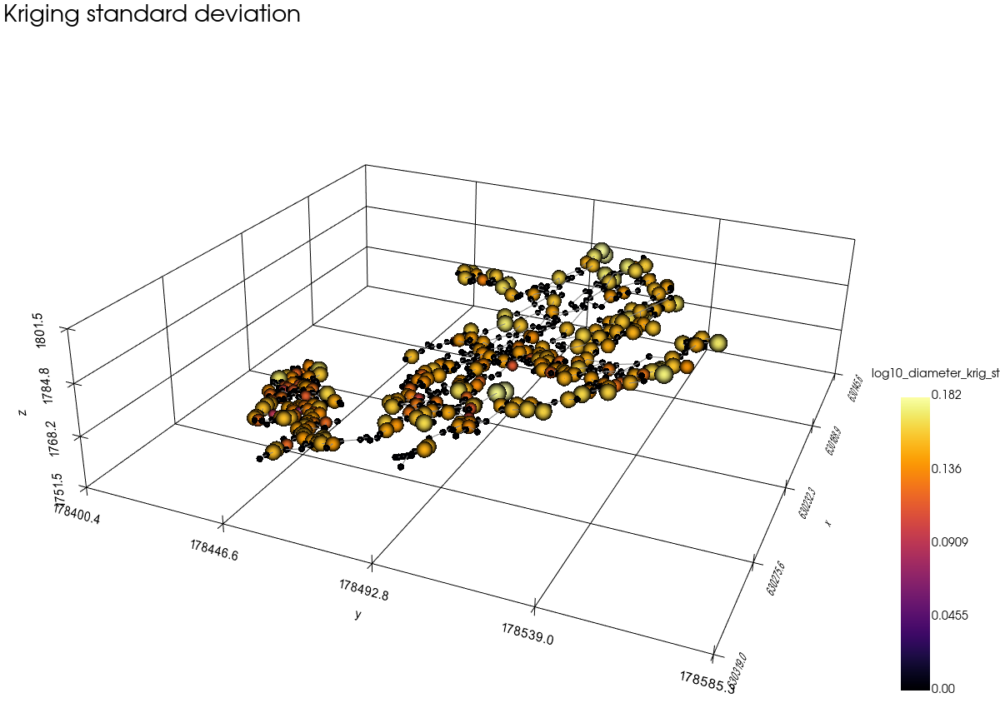

In [27]:
# Original graph
# --------------

# Attribute to be plotted
node_attr = node_attr_krig_std

# Color map for node attribute
cmap = plt.get_cmap('inferno')
# cmap.set_over('gold')       # color for value above upper limit 'vmax' (if specified)
# cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
# cmap.set_bad('red', alpha=1.0) # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 1
size_max = 3
size_nan = 2
exponent = 2
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options_nodes = {
    'point_size' : node_size,  # node size
    'cmap'       : cmap,       # node color map
    #'vmin':-1.2
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=(1200, 850), notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':node_attr+'\n', 'title_font_size':14, 'label_font_size':14, 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text('Kriging standard deviation', font_size=12)

cpos = pp.show(cpos=cpos, return_cpos=True)


### Sequential Gaussian Simulation (SGS)

The function `kn.tools.sgs_node_attribute[_mp]` do SGS on the nodes of a graph. 

*Note: `kn.tools.sgs_node_attribute` is serial and `kn.tools.sgs_node_attribute_mp` use multiprocessing.*

In [28]:
# SGS - parallel

# Attribute to simulate
node_attr = 'log10_diameter'

# Parameters
# ----------
# Kriging type
# method = 'ordinary_kriging'
method = 'simple_kriging'
# Note : with simple krging, if the mean is not specified, it is set to the mean of the known values of the node attribute

# Neighborhood parameters
use_unique_neighborhood = False # if True all nodes are taken into account for kriging (no neighborhood search)
nneighborMax = 12      # Maximal number of neighbors (if use_unique_neighborhood=False)
searchRadius = 200.0   # Maximal distance to search for neighbors (if use_unique_neighborhood=False)

nreal = 100  # number of realizations (SGS)
seed = 8724 # seed for reproducibility

# Node attributes for results of SGS
node_attr_sgs = node_attr + '_sgs'

nproc = 4 # number of processes (multiprocessing)

t1 = time.time()
sgs = kn.tools.sgs_node_attribute_mp(
        G,         # Graph
        cov_model, # covariance model used (function)
        node_attr, # Node attribute to be kriged
        edge_length_attr='length', # Edge attribute used for distance computation
        method=method,
        nneighborMax=nneighborMax,
        searchRadius=searchRadius,
        nreal=nreal,
        seed=seed,
        update_graph=True, # if True, add one new node attribute in the graph (array of SGS realizations)
        sgs_node_attr=node_attr_sgs,
        nproc=nproc,
        verbose=1)
t2 = time.time()
print(f'SGS {nreal} realizations ({nproc} processes) - Elapsed time: {t2-t1:.3g} sec')

Running `sgs_node_attr` on 4 processes...
[pid=0] SGS:   1% (  0 realizations done of 25)
[pid=0] SGS:   2% (  0 realizations done of 25)
[pid=0] SGS:   3% (  0 realizations done of 25)
[pid=0] SGS:   4% (  1 realizations done of 25)
[pid=0] SGS:   5% (  1 realizations done of 25)
[pid=0] SGS:   6% (  1 realizations done of 25)
[pid=0] SGS:   7% (  1 realizations done of 25)
[pid=0] SGS:   8% (  2 realizations done of 25)
[pid=0] SGS:   9% (  2 realizations done of 25)
[pid=0] SGS:  10% (  2 realizations done of 25)
[pid=0] SGS:  11% (  2 realizations done of 25)
[pid=0] SGS:  12% (  3 realizations done of 25)
[pid=0] SGS:  13% (  3 realizations done of 25)
[pid=0] SGS:  14% (  3 realizations done of 25)
[pid=0] SGS:  15% (  3 realizations done of 25)
[pid=0] SGS:  16% (  4 realizations done of 25)
[pid=0] SGS:  17% (  4 realizations done of 25)
[pid=0] SGS:  18% (  4 realizations done of 25)
[pid=0] SGS:  19% (  4 realizations done of 25)
[pid=0] SGS:  20% (  5 realizations done of 25

In [29]:
# Compute mean and std of simulations
node_attr_sgs_mean = node_attr_sgs + '_mean' 
node_attr_sgs_std = node_attr_sgs + '_std' 

sgs = nx.get_node_attributes(G, node_attr_sgs)

nsgs = len(sgs[list(G.nodes())[0]])

sgs_mean = {u:float(np.asarray(sgs[u]).mean()) for u in G.nodes()}
sgs_std = {u:float(np.asarray(sgs[u]).std()) for u in G.nodes()}

nx.set_node_attributes(G, sgs_mean, node_attr_sgs_mean)
nx.set_node_attributes(G, sgs_std, node_attr_sgs_std)


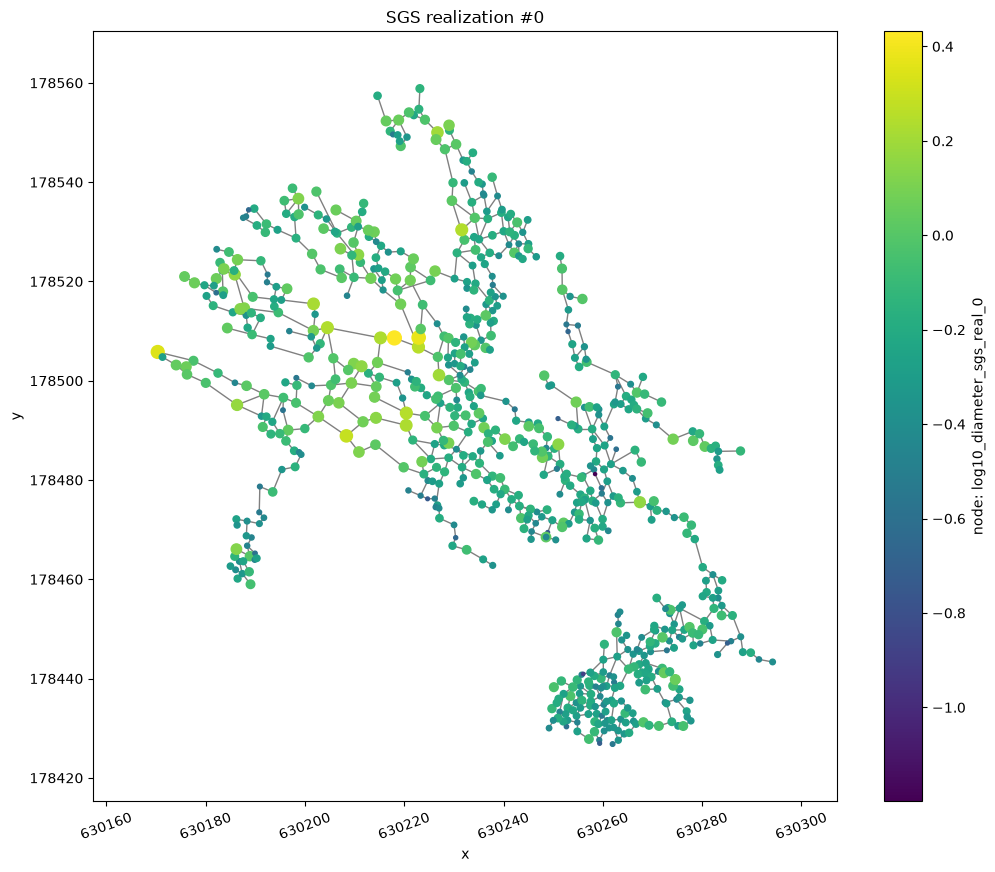

In [30]:
# Index of the realization to be plotted
index = 0

node_attr = f'{node_attr_sgs}_real_{index}' # temporary attribute: attribute to be plotted

sgs = nx.get_node_attributes(G, node_attr_sgs) # list of realization at each node
nx.set_node_attributes(G, {u:sgs[u][index] for u in G.nodes()}, node_attr) # Store the realization

# 2D plot
# -------
# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 5
size_max = 100
size_nan = 1
exponent = 3
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options = {
    'node_size'   : node_size,  # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}

plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    G,
    # node_attr='log10_diameter', # before simulation
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title(f'SGS realization #{index}')
plt.axis('equal')
plt.show()



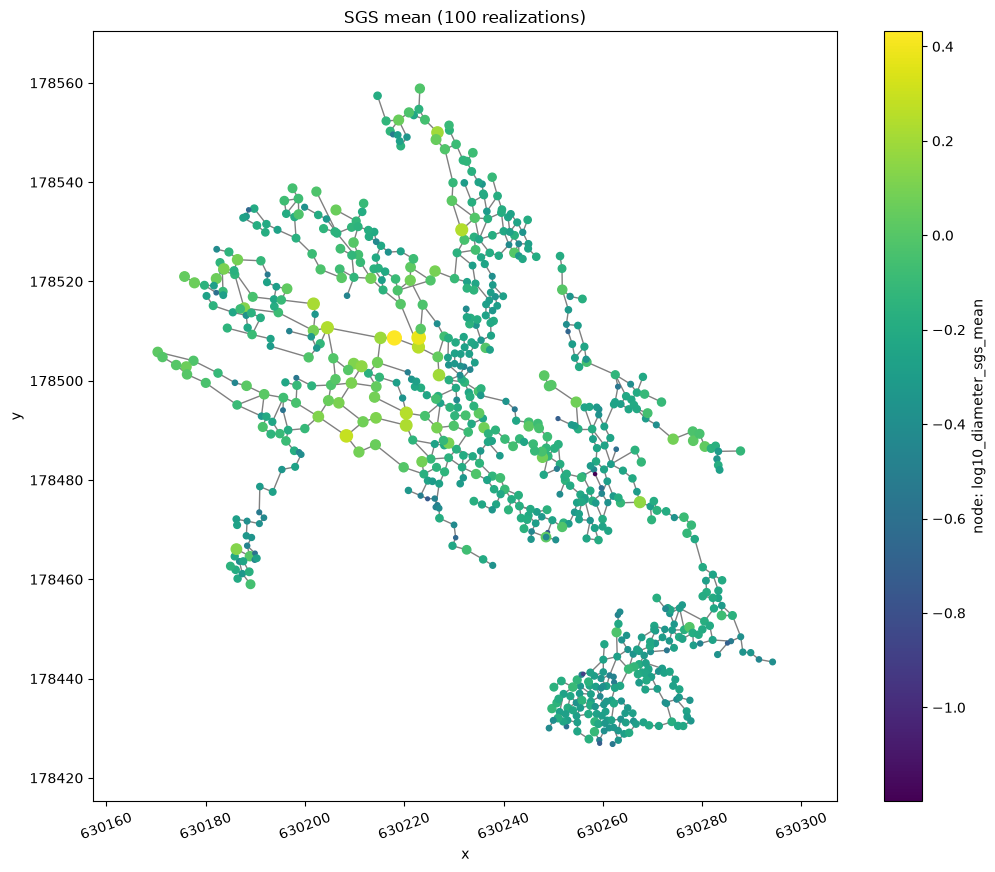

In [31]:
# Attribute to be plotted
node_attr = node_attr_sgs_mean

# 2D plot
# -------
# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 5
size_max = 100
size_nan = 1
exponent = 3
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options = {
    'node_size'   : node_size,  # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}

plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    G,
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title(f'SGS mean ({nsgs} realizations)')
plt.axis('equal')
plt.show()


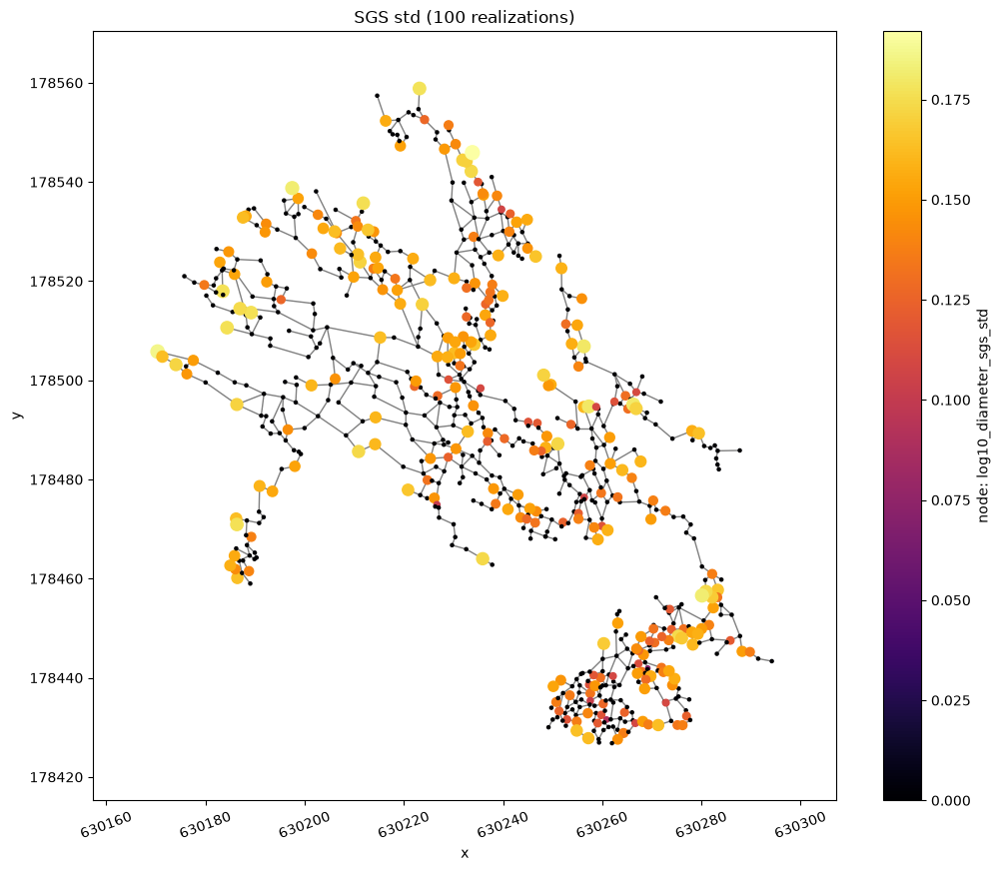

In [32]:
# Attribute to be plotted
node_attr = node_attr_sgs_std

# 2D plot
# -------
# Color map for node attribute
cmap = plt.get_cmap('inferno')
# cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
# cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
# cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 5
size_max = 100
size_nan = 1
exponent = 3
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options = {
    'node_size'   : node_size,  # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}


plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    G,
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title(f'SGS std ({nsgs} realizations)')
plt.axis('equal')
plt.show()


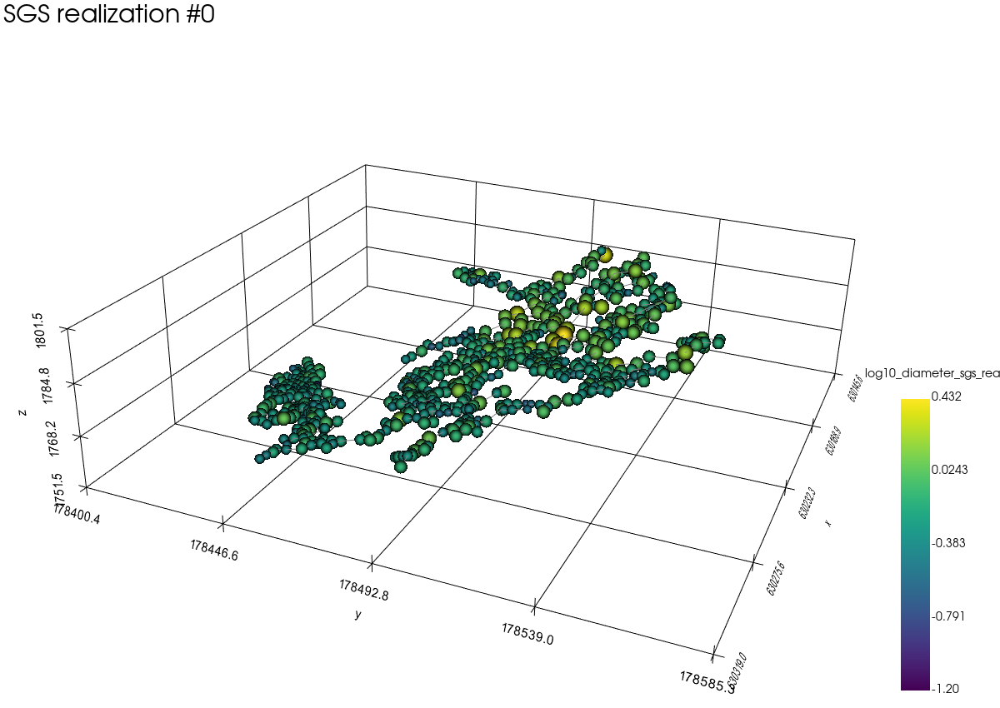

In [33]:
# Index of the realization to be plotted
index = 0

node_attr = f'{node_attr_sgs}_real_{index}' # temporary attribute: attribute to be plotted

sgs = nx.get_node_attributes(G, node_attr_sgs) # list of realization at each node
nx.set_node_attributes(G, {u:sgs[u][index] for u in G.nodes()}, node_attr) # Store the realization

# 3D plot
# -------
# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold')       # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red', alpha=1.0) # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 1
size_max = 3
size_nan = 2
exponent = 2
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options_nodes = {
    'point_size' : node_size,  # node size
    'cmap'       : cmap,       # node color map
    #'vmin':-1.2
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=None, notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':node_attr+'\n', 'title_font_size':14, 'label_font_size':14, 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text(f'SGS realization #{index}', font_size=12)
pp.scalar_bar.GetTitleTextProperty().SetLineSpacing(1.2) # to add space between scalar bar title and scalar bar (with '\n' in title)

pp.show(cpos=cpos)



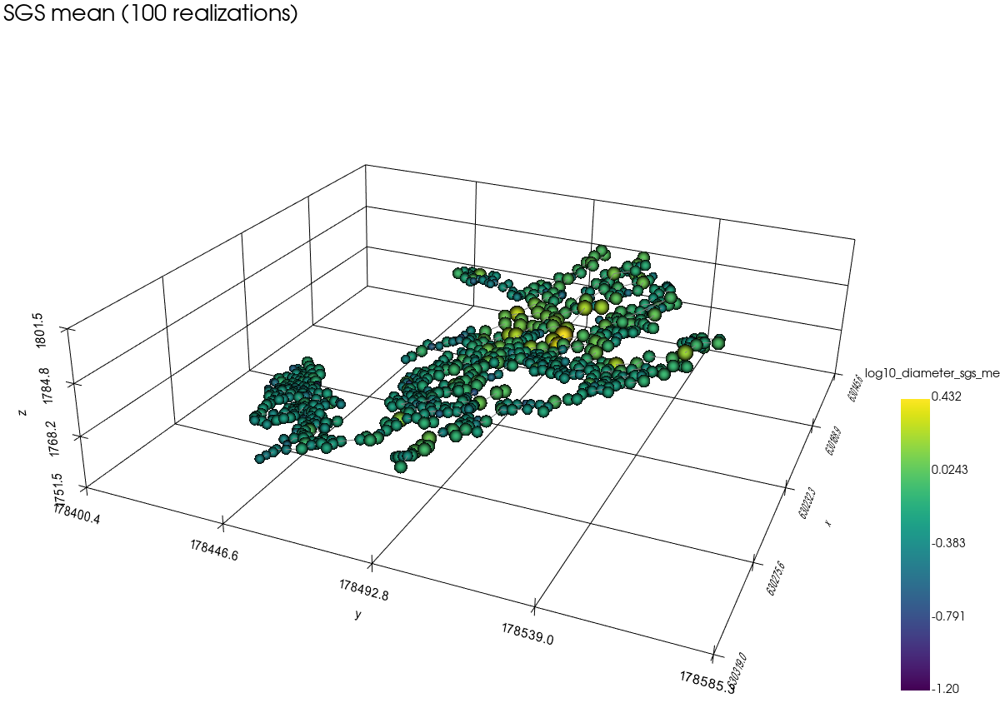

In [34]:
# Attribute to be plotted
node_attr = node_attr_sgs_mean

# 3D plot
# -------
# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold')       # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red', alpha=1.0) # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 1
size_max = 3
size_nan = 2
exponent = 2
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options_nodes = {
    'point_size' : node_size,  # node size
    'cmap'       : cmap,       # node color map
    #'vmin':-1.2
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=None, notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':node_attr+'\n', 'title_font_size':14, 'label_font_size':14, 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text(f'SGS mean ({nsgs} realizations)', font_size=12)
pp.scalar_bar.GetTitleTextProperty().SetLineSpacing(1.2) # to add space between scalar bar title and scalar bar (with '\n' in title)

pp.show(cpos=cpos)



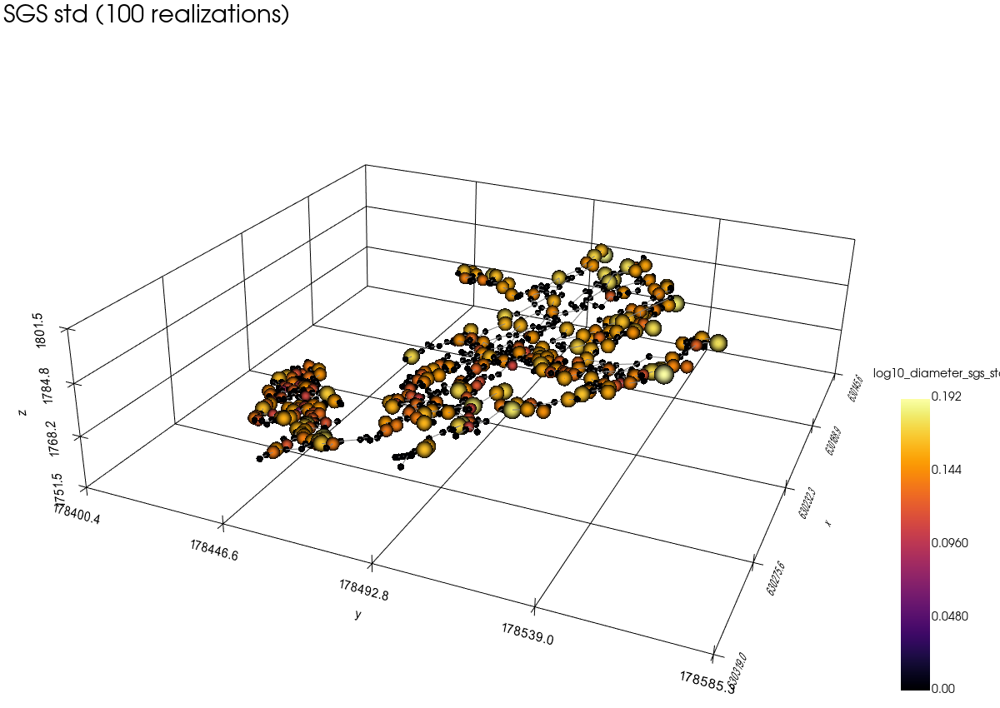

In [35]:
# Attribute to be plotted
node_attr = node_attr_sgs_std

# 3D plot
# -------
# Color map for node attribute
cmap = plt.get_cmap('inferno')
# cmap.set_over('gold')       # color for value above upper limit 'vmax' (if specified)
# cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
# cmap.set_bad('red', alpha=1.0) # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 1
size_max = 3
size_nan = 2
exponent = 2
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options_nodes = {
    'point_size' : node_size,  # node size
    'cmap'       : cmap,       # node color map
    #'vmin':-1.2
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=None, notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':node_attr+'\n', 'title_font_size':14, 'label_font_size':14, 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text(f'SGS std ({nsgs} realizations)', font_size=12)
pp.scalar_bar.GetTitleTextProperty().SetLineSpacing(1.2) # to add space between scalar bar title and scalar bar (with '\n' in title)

pp.show(cpos=cpos)



### Compare results
- kriging estimates and initial values (before removing)
- mean of simulations and kriging estimates
- standard deviation of simulations and kriging standard deviation

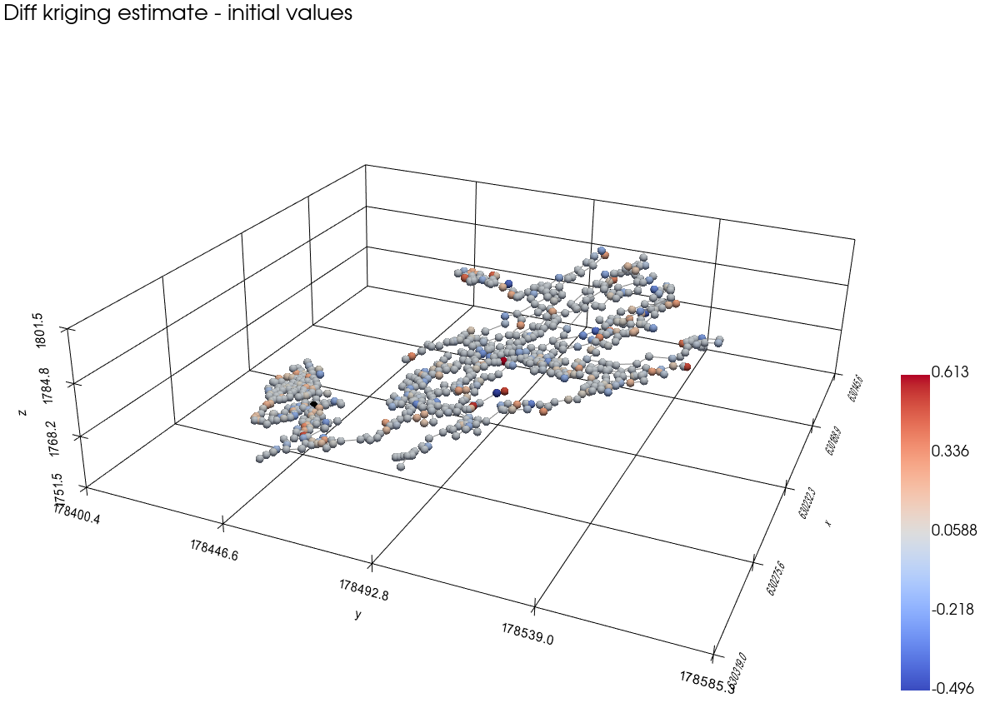

In [36]:
# Difference between SGS mean and initial values
# ------------------------------------------------
d1 = nx.get_node_attributes(G, node_attr_krig_est)
d2 = node_attr_dict_save
nx.set_node_attributes(G, {u:d1[u]-d2[u] for u in G.nodes()}, '_tmp_') # Store the realization as '_tmp_' (temporary attribute)
node_attr = '_tmp_'

# 3D plot
# -------
options_nodes = {
    'point_size' : 10,         # node size
    'cmap'       : 'coolwarm', # node color map
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=None, notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':'', 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text(f'Diff kriging estimate - initial values', font_size=12)
pp.scalar_bar.GetTitleTextProperty().SetLineSpacing(1.2) # to add space between scalar bar title and scalar bar (with '\n' in title)

pp.show(cpos=cpos)



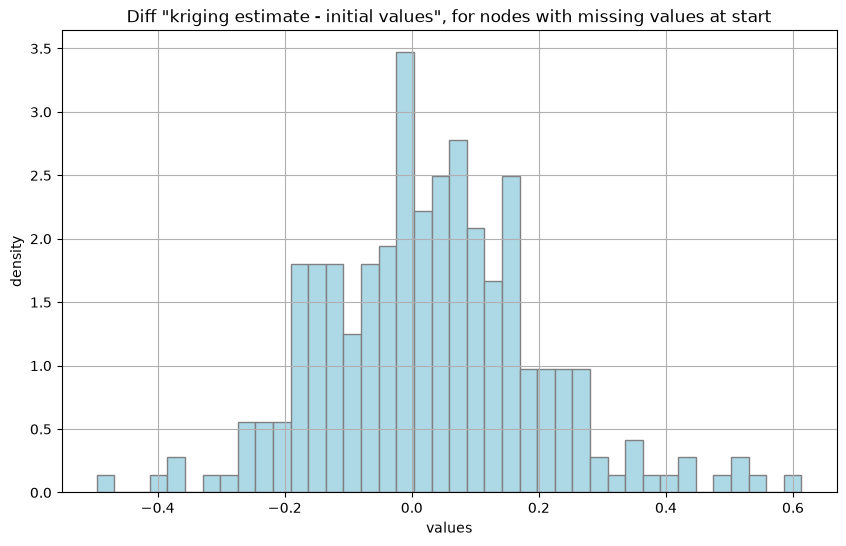

In [37]:
# Histogram
plt.figure(figsize=(10, 6))
plt.hist(np.asarray([d1[u] - d2[u] for u in nodes_with_missing_values]), density=True, bins=40, color='lightblue', edgecolor='gray')
plt.xlabel('values')
plt.ylabel('density')
plt.title('Diff "kriging estimate - initial values", for nodes with missing values at start')
plt.grid()
plt.show()

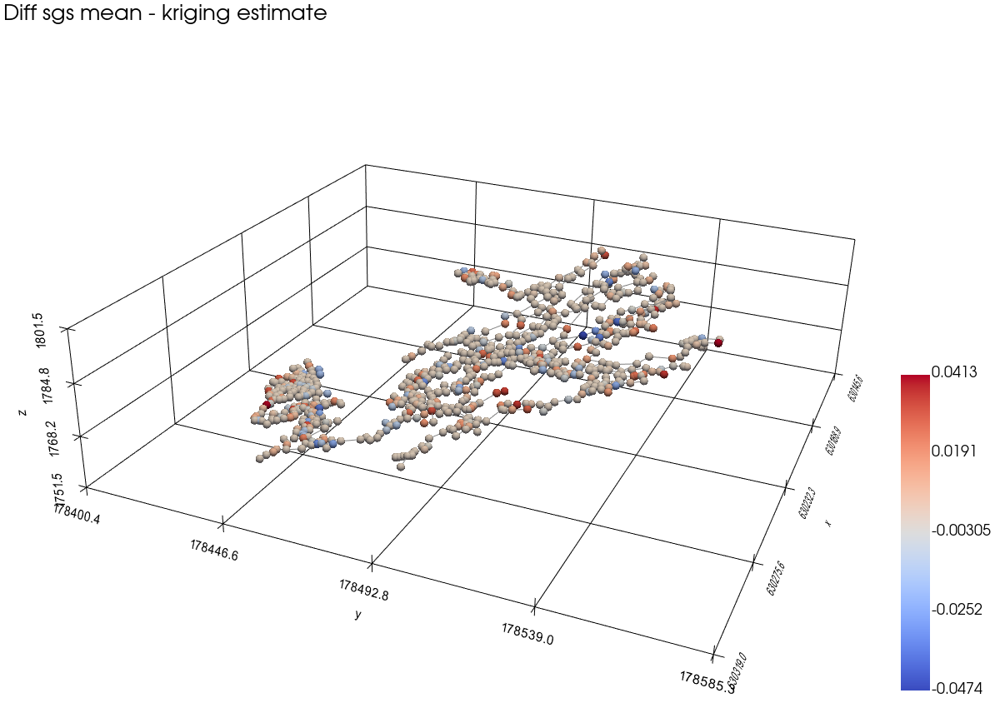

In [38]:
# Difference between SGS mean and Kriging estimate
# ------------------------------------------------
d1 = nx.get_node_attributes(G, node_attr_sgs_mean)
d2 = nx.get_node_attributes(G, node_attr_krig_est)
nx.set_node_attributes(G, {u:d1[u]-d2[u] for u in G.nodes()}, '_tmp_') # Store the realization as '_tmp_' (temporary attribute)
node_attr = '_tmp_'

# 3D plot
# -------
options_nodes = {
    'point_size' : 10,         # node size
    'cmap'       : 'coolwarm', # node color map
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=None, notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':'', 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text(f'Diff sgs mean - kriging estimate', font_size=12)
pp.scalar_bar.GetTitleTextProperty().SetLineSpacing(1.2) # to add space between scalar bar title and scalar bar (with '\n' in title)

pp.show(cpos=cpos)



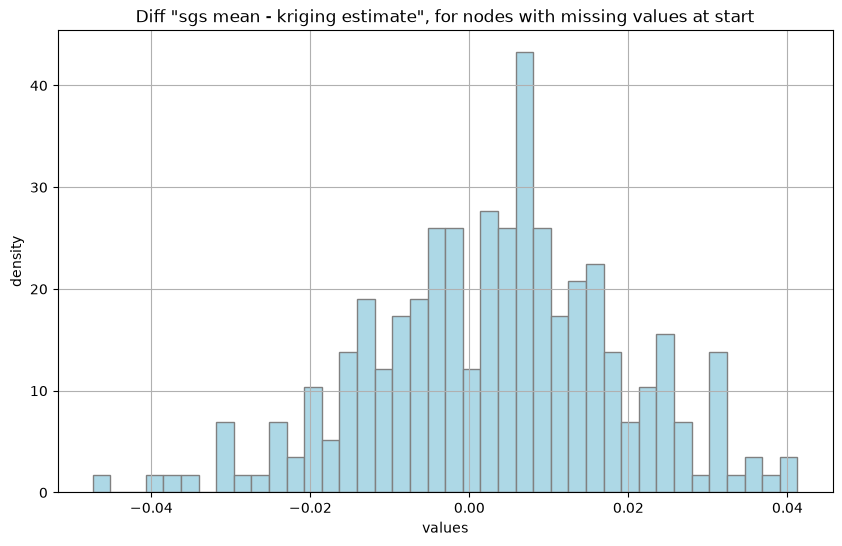

In [39]:
# Histogram
plt.figure(figsize=(10, 6))
plt.hist(np.asarray([d1[u] - d2[u] for u in nodes_with_missing_values]), density=True, bins=40, color='lightblue', edgecolor='gray')
plt.xlabel('values')
plt.ylabel('density')
plt.title('Diff "sgs mean - kriging estimate", for nodes with missing values at start')
plt.grid()
plt.show()

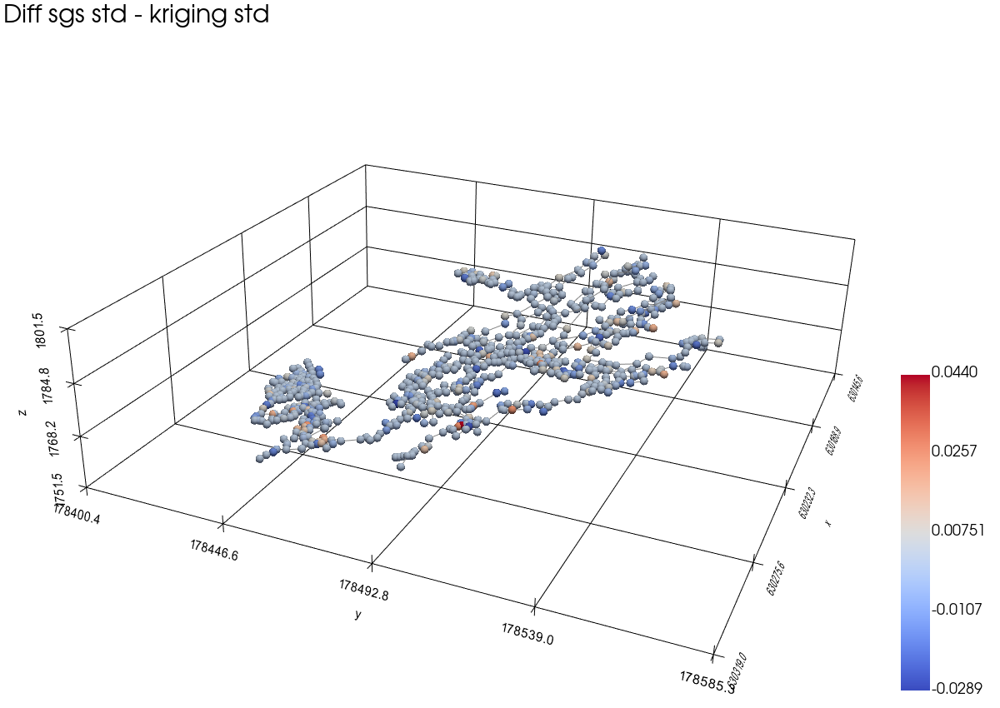

In [40]:
# Difference between SGS std and Kriging std
# ------------------------------------------
d1 = nx.get_node_attributes(G, node_attr_sgs_std)
d2 = nx.get_node_attributes(G, node_attr_krig_std)
nx.set_node_attributes(G, {u:d1[u]-d2[u] for u in G.nodes()}, '_tmp_') # Store the realization as '_tmp_' (temporary attribute)
node_attr = '_tmp_'

# 3D plot
# -------
options_nodes = {
    'point_size' : 10,         # node size
    'cmap'       : 'coolwarm', # node color map
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=None, notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':'', 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text(f'Diff sgs std - kriging std', font_size=12)
pp.scalar_bar.GetTitleTextProperty().SetLineSpacing(1.2) # to add space between scalar bar title and scalar bar (with '\n' in title)

pp.show(cpos=cpos)



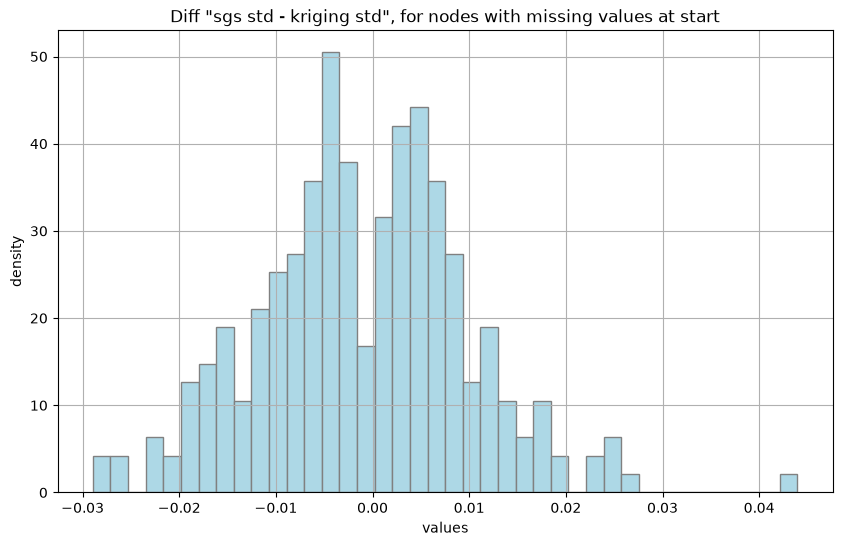

In [41]:
# Histogram
plt.figure(figsize=(10, 6))
plt.hist(np.asarray([d1[u] - d2[u] for u in nodes_with_missing_values]), density=True, bins=40, color='lightblue', edgecolor='gray')
plt.xlabel('values')
plt.ylabel('density')
plt.title('Diff "sgs std - kriging std", for nodes with missing values at start')
plt.grid()
plt.show()

## 4. Reconstruction of missing data (II)

We proceed in two steps, the idea is to "distinguishing" the branches of the graph.

We consider the graph of branches where a node represents a branch in the original graph (labeled by integers from 0) and an edge exists between two nodes if the two represented branches have a common extremity (in the original graph). 

For the considered property on the original graph
The strategy:
- estimate a target mean value of the considered property over each branch of the original graph:
    - for each branch: take the mean of the known values at the original graph nodes in the branch
    - if needed, i.e. if a branch has no known value: assign the known mean values (from the point above) to the corresponding nodes of the graph of branches and krige this new property on the graph of branches, to get a mean for each branch of the original graph
    - migrate the mean value from branches to original graph nodes (target mean)
- do a variogram analysis intra-branch (considering pair of nodes within a same branch) on the original graph and fit a covariance model
- krige / simulate missing values on the original graph node, while restraining the neighborhood to the branch containing the estimated / simulated node, based on simple kriging with mean at nodes set to the target mean (computed at first step)

## 4.1 Estimate mean over the branches


### Compute mean on branches with at least one value
Set mean of the considered property as a node attribute on the graph of branches.


In [42]:
node_attr = 'log10_diameter'

# Compute mean over each branch in the original graph, and set it as a new node attribute in the graph of branches
d = {i: float(np.nanmean(np.asarray([G.nodes[u][node_attr] for u in br]))) for i, br in enumerate(kg.branches)}
# Note: we get a warinng if there is branches with only nan values

nx.set_node_attributes(Gb, d, node_attr + '_mean')


/tmp/ipykernel_25942/3140167895.py:4: RuntimeWarning: Mean of empty slice
  d = {i: float(np.nanmean(np.asarray([G.nodes[u][node_attr] for u in br]))) for i, br in enumerate(kg.branches)}


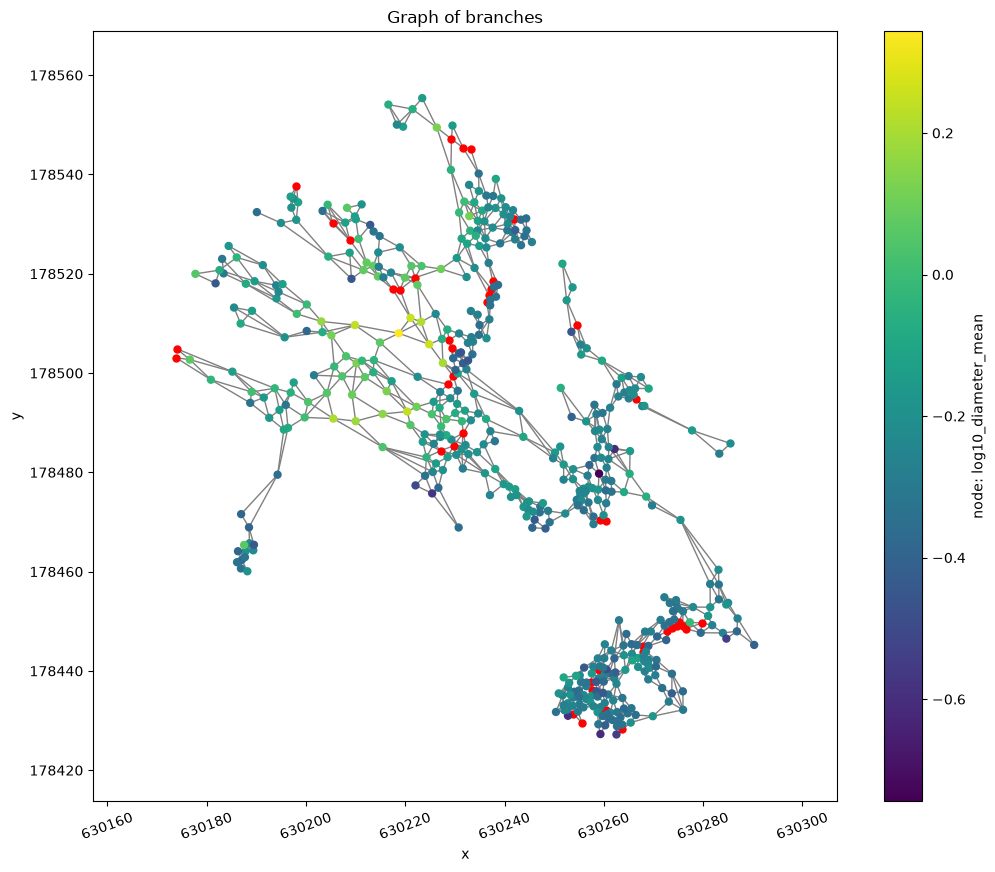

In [43]:
# Graph of branches
# -----------------

# Attribute to be plotted
node_attr = 'log10_diameter_mean'

# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)


options = {
    'node_size'   : 25,         # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}

plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    Gb,
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title('Graph of branches')
plt.axis('equal')
plt.show(block=True)


### Set a covariance model for "mean" in the graph of branches



In [44]:
# Variogram analysis on the graph of branches
# -------------------------------------------
node_attr = 'log10_diameter_mean'
hmax = 10                   # maximal distance for pair of nodes (in number of edges)

ncla = 10                   # number of classes for variogram experimental computation
nsample_start_nodes = 5000 # number of starting node (inducing pairs) to sample for variogram cloud computation
seed = 224                 # random seed for reproducibility


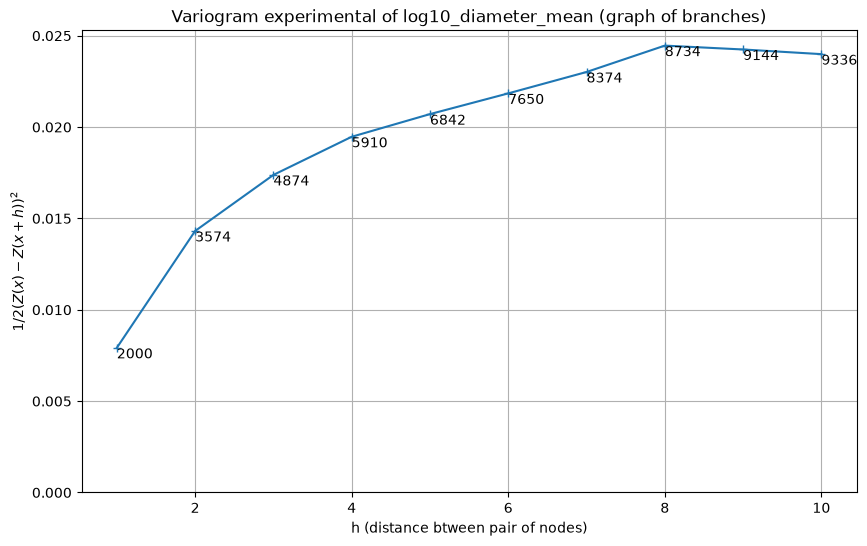

In [45]:
# Variogram cloud
Gb_h, Gb_gamma, Gb_npair = kn.tools.variogram_cloud(
                                Gb, 
                                node_attr=node_attr,
                                edge_length_attr=None, # 1 for each edge 
                                nsample_start_nodes=nsample_start_nodes,
                                hmax=hmax, 
                                seed=seed,
                                make_plot=False,
                                verbose=0)

plt.figure(figsize=(10, 6))
# Variogram experimental computation from variogram cloud
Gb_hexp, Gb_gexp, Gb_nexp = kn.tools.variogram_exp_from_variogram_cloud(
                        variogramCloud=(Gb_h, Gb_gamma, Gb_npair),
                        ncla=ncla,
                        hmax=hmax,
                        make_plot=True,
                        show_count=True,
                        color='tab:blue')
plt.ylim(bottom=0)
plt.grid()
plt.title('Variogram experimental of ' + node_attr + ' (graph of branches)')
plt.show()

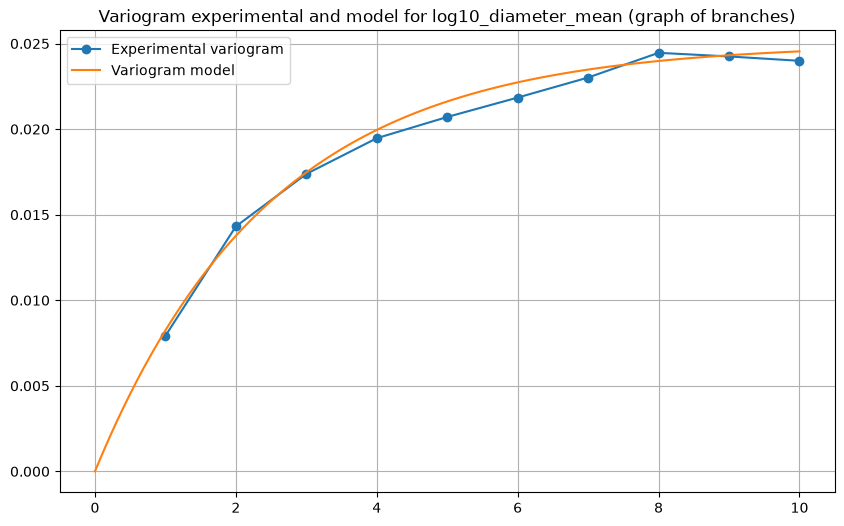

In [46]:
# Fit a covariance model / variogram model (for graph of branches)

def Gb_cov_model(h):
    return kn.tools.cov_exp(h, w=0.025, r=7.5)

h = np.linspace(0, hmax, 100)
Gb_vario_model_h = Gb_cov_model(0) - Gb_cov_model(h)

plt.figure(figsize=(10, 6))

plt.plot(Gb_hexp, Gb_gexp, 'o-', label='Experimental variogram')
plt.plot(h, Gb_vario_model_h, '-', label='Variogram model')

plt.grid()
plt.legend()
plt.title('Variogram experimental and model for ' + node_attr + ' (graph of branches)')
plt.show()

### Kriging "mean" on the graph of branches


In [47]:
# Kriging - parallel

# Attribute to be kriged
node_attr = 'log10_diameter_mean'

# Parameters
# ----------
# Kriging type
# method = 'ordinary_kriging'
method = 'simple_kriging'
# Note : with simple krging, if the mean is not specified, it is set to the mean of the known values of the node attribute

# Neighborhood parameters
use_unique_neighborhood = False # if True all nodes are taken into account for kriging (no neighborhood search)
nneighborMax = 12      # Maximal number of neighbors (if use_unique_neighborhood=False)
searchRadius = 200.0   # Maximal distance to search for neighbors (if use_unique_neighborhood=False)

nproc = 4 # number of processes (multiprocessing)

# Node attributes for results of kriging
node_attr_krig_est = node_attr + '_krig_est' # kriging estimate
node_attr_krig_std = node_attr + '_krig_std' # kriging standard deviation

t1 = time.time()
krig_est, krig_std = kn.tools.krige_node_attribute_mp(
        Gb,         # Graph
        Gb_cov_model, # covariance model used (function)
        node_attr, # Node attribute to be kriged
        edge_length_attr=None, # Edge attribute used for distance computation
        method=method,
        use_unique_neighborhood=use_unique_neighborhood,
        nneighborMax=nneighborMax,
        searchRadius=searchRadius,
        update_graph=True, # if True, add two new node attributes in the graph (kriging estimate and std)
        kriging_est_node_attr=node_attr_krig_est,
        kriging_std_node_attr=node_attr_krig_std,
        nproc=nproc,
        verbose=1)
t2 = time.time()
print(f'Kriging [on graph of branches] ({nproc} processes) - Elapsed time: {t2-t1:.3g} sec')

Running `krige_node_attribute` on 4 processes...
[pid=0] Kriging:   1%
[pid=0] Kriging:   2%
[pid=0] Kriging:   3%
[pid=0] Kriging:   4%
[pid=0] Kriging:   5%
[pid=0] Kriging:   6%
[pid=0] Kriging:   7%
[pid=0] Kriging:   8%
[pid=0] Kriging:   9%
[pid=0] Kriging:  10%
[pid=0] Kriging:  11%
[pid=0] Kriging:  12%
[pid=0] Kriging:  13%
[pid=0] Kriging:  14%
[pid=0] Kriging:  15%
[pid=0] Kriging:  16%
[pid=0] Kriging:  17%
[pid=0] Kriging:  18%
[pid=0] Kriging:  19%
[pid=0] Kriging:  20%
[pid=0] Kriging:  21%
[pid=0] Kriging:  22%
[pid=0] Kriging:  23%
[pid=0] Kriging:  24%
[pid=0] Kriging:  25%
[pid=0] Kriging:  26%
[pid=0] Kriging:  27%
[pid=0] Kriging:  28%
[pid=0] Kriging:  29%
[pid=0] Kriging:  30%
[pid=0] Kriging:  31%
[pid=0] Kriging:  32%
[pid=0] Kriging:  33%
[pid=0] Kriging:  34%
[pid=0] Kriging:  35%
[pid=0] Kriging:  36%
[pid=0] Kriging:  37%
[pid=0] Kriging:  38%
[pid=0] Kriging:  39%
[pid=0] Kriging:  40%
[pid=0] Kriging:  41%
[pid=0] Kriging:  42%
[pid=0] Kriging:  43%
[pid=

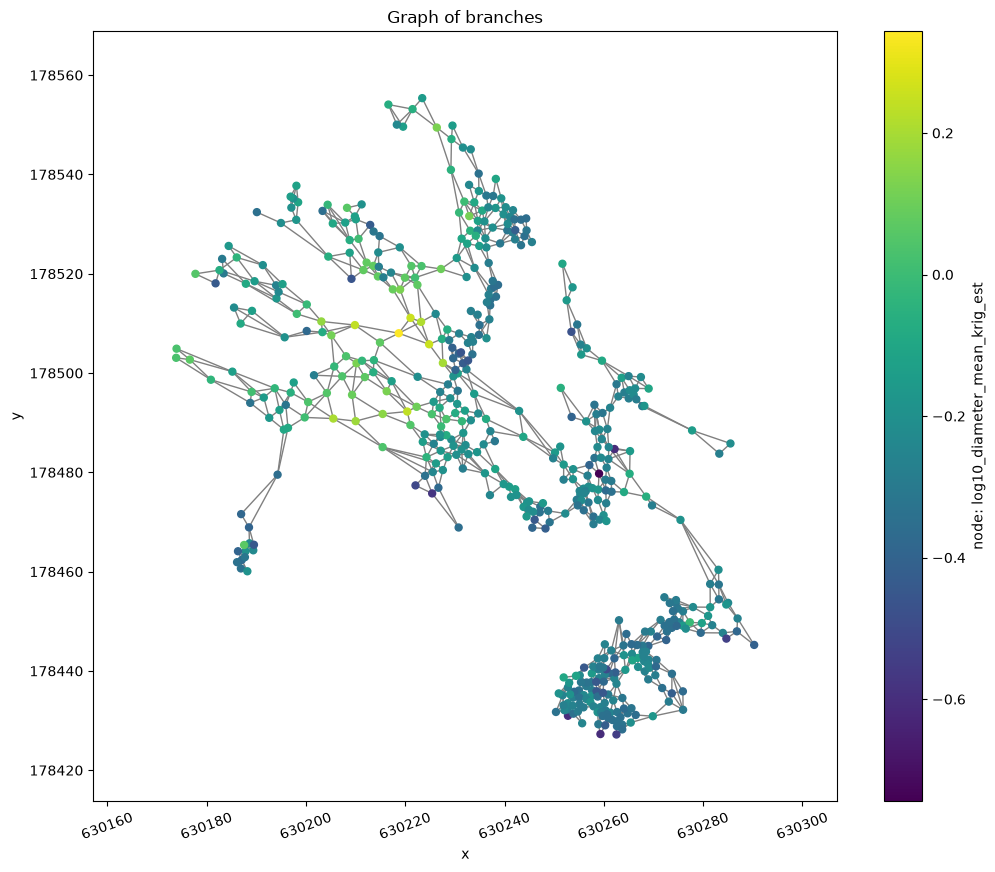

In [48]:
# Graph of branches
# -----------------

# Attribute to be plotted
node_attr = node_attr_krig_est

# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)


options = {
    'node_size'   : 25,         # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}

plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    Gb,
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title('Graph of branches')
plt.axis('equal')
plt.show(block=True)


### Migration (result of kriging) from graph of branches to original graph
The values on branches (branch values) is known by the kriging above. On a node in the original graph, the value is set to the average of the branch values considering all branches containing the node, and weighted by the number of original nodes in each branch.


In [49]:
# Set a target mean on each node, from the mean over the branches (result of kriging above)
Gb_node_attr = node_attr_krig_est
node_attr = 'log10_diameter_target_mean'

target_mean = {}

br_weights = np.asarray([len(br) for br in kg.branches], dtype='float')
for u in G.nodes():
    br_ids = G.nodes[u]['branch_ids_list']
    tmp_mean = np.asarray([Gb.nodes[id][Gb_node_attr] for id in br_ids])
    weights = br_weights[br_ids]
    target_mean[u] = float(np.average(tmp_mean, weights=weights))

nx.set_node_attributes(G, target_mean, node_attr)


## 4.2 Variogram analysis intra branches

Note that this step is independent of the step 4.1

The methods `variogram_cloud_intra_branches` and `variogram_exp_intra_branches` of a `KGraph` object allow to compute for a given node property respectively the variogram cloud and the experimental variogram intra branches, i.e. only the pairs of points within a same branch are considered, accounting for the real length (sum of the lengths of the edges between the two points).

*Note. A branch of a graph is a path where all the nodes except the two extremities are nodes of degree 2.*

### Experimental variogram

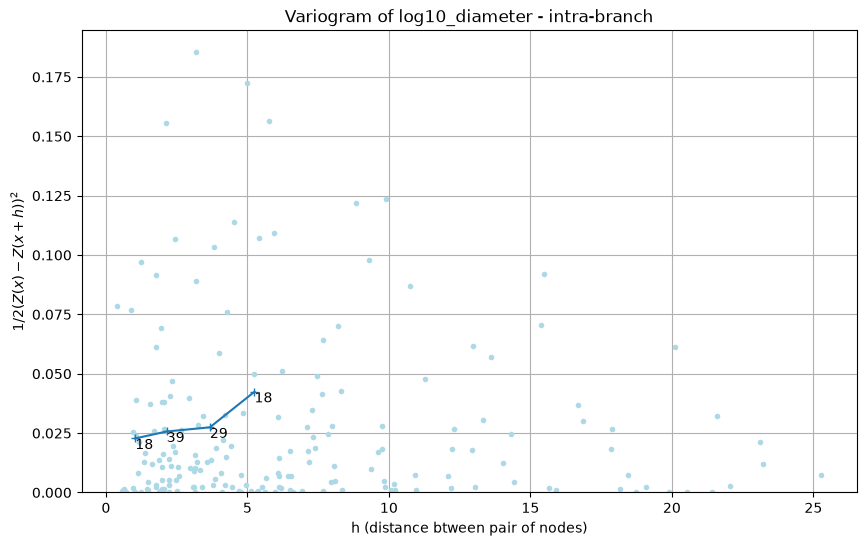

In [50]:
node_attr = 'log10_diameter'
hmax = 6                # maximal distance for pair of nodes
ncla = 4                 # number of classes for variogram experimental computation

# Variogram experimental
plt.figure(figsize=(10, 6))

# Variogram cloud - Using method of KGraph object
h_intra, gamma_intra, npair_intra = kg.variogram_cloud_intra_branches(
                        node_attr=node_attr,
                        exclude_branch_extremities=True,
                        hmax=None,
                        make_plot=True,
                        color='lightblue')

# Variogram experimental - from the variogram cloud    
hexp_intra, gexp_intra, nexp_intra = kn.tools.variogram_exp_from_variogram_cloud(
                        variogramCloud=(h_intra, gamma_intra, npair_intra),
                        ncla=ncla,
                        hmax=hmax,
                        make_plot=True,
                        show_count=True,
                        color='tab:blue')

plt.grid()
plt.title('Variogram of ' + node_attr + ' - intra-branch')
plt.show()

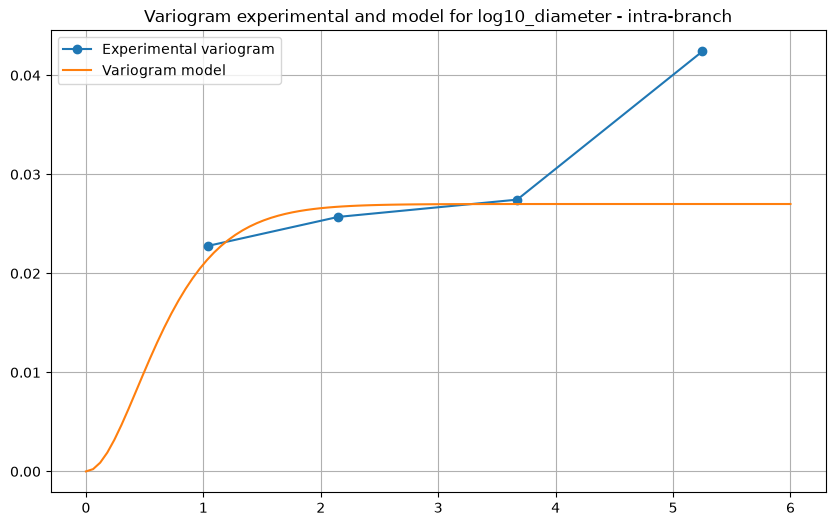

In [51]:
# Fit a covariance model / variogram model

def cov_model_intra(h):
    return kn.tools.cov_matern(h, w=0.027, r=0.6, nu=2.5)

h = np.linspace(0, hmax, 100)
vario_model_intra_h = cov_model_intra(0) - cov_model_intra(h)

plt.figure(figsize=(10, 6))


plt.plot(hexp_intra, gexp_intra, 'o-', label='Experimental variogram')
plt.plot(h, vario_model_intra_h, '-', label='Variogram model')

plt.grid()
plt.legend()
plt.title('Variogram experimental and model for ' + node_attr + ' - intra-branch')
plt.show()

## 4.3. Kriging and simulation (SGS)



### Kriging

The function `kn.tools.krige_node_attribute[_mp]` do kriging on the nodes of a graph. The keyword argument `neighbors_on_same_branch_only=True` is used with the keyword argument `branches=kg.branches` to restrain the neighborhood to the current branch.

*Note: `kn.tools.krige_node_attribute` is serial and `kn.tools.krige_node_attribute_mp` use multiprocessing.*

In [52]:
# Kriging - parallel

# Attribute to be kriged
node_attr = 'log10_diameter'

# Parameters
# ----------
# Kriging type
# method = 'ordinary_kriging'
method = 'simple_kriging'
mean = 'log10_diameter_target_mean' # target mean (see step 4.1 above)

# Neighborhood parameters
use_unique_neighborhood = False # if True all nodes are taken into account for kriging (no neighborhood search)
nneighborMax = 12      # Maximal number of neighbors (if use_unique_neighborhood=False)
searchRadius = 200.0   # Maximal distance to search for neighbors (if use_unique_neighborhood=False)

nproc = 4 # number of processes (multiprocessing)

# Node attributes for results of kriging
node_attr_krig_est = node_attr + '_intra_krig_est' # kriging estimate
node_attr_krig_std = node_attr + '_intra_krig_std' # kriging standard deviation

t1 = time.time()
krig_est, krig_std = kn.tools.krige_node_attribute_mp(
        G,         # Graph
        cov_model_intra, # covariance model used (function)
        node_attr, # Node attribute to be kriged
        edge_length_attr='length', # Edge attribute used for distance computation
        method=method,
        mean=mean,
        neighbors_on_same_branch_only=True,
        branches=kg.branches,
        use_unique_neighborhood=use_unique_neighborhood,
        nneighborMax=nneighborMax,
        searchRadius=searchRadius,
        update_graph=True, # if True, add two new node attributes in the graph (kriging estimate and std)
        kriging_est_node_attr=node_attr_krig_est,
        kriging_std_node_attr=node_attr_krig_std,
        nproc=nproc,
        verbose=1)
t2 = time.time()
print(f'Kriging ({nproc} processes) - Elapsed time: {t2-t1:.3g} sec')

Running `krige_node_attribute` on 4 processes...
[pid=0] Kriging:   1%
[pid=0] Kriging:   2%
[pid=0] Kriging:   3%
[pid=0] Kriging:   4%
[pid=0] Kriging:   5%
[pid=0] Kriging:   6%
[pid=0] Kriging:   7%
[pid=0] Kriging:   8%
[pid=0] Kriging:   9%
[pid=0] Kriging:  10%
[pid=0] Kriging:  11%
[pid=0] Kriging:  12%
[pid=0] Kriging:  13%
[pid=0] Kriging:  14%
[pid=0] Kriging:  15%
[pid=0] Kriging:  16%
[pid=0] Kriging:  17%
[pid=0] Kriging:  18%
[pid=0] Kriging:  19%
[pid=0] Kriging:  20%
[pid=0] Kriging:  21%
[pid=0] Kriging:  22%
[pid=0] Kriging:  23%
[pid=0] Kriging:  24%
[pid=0] Kriging:  25%
[pid=0] Kriging:  26%
[pid=0] Kriging:  27%
[pid=0] Kriging:  28%
[pid=0] Kriging:  29%
[pid=0] Kriging:  30%
[pid=0] Kriging:  31%
[pid=0] Kriging:  32%
[pid=0] Kriging:  33%
[pid=0] Kriging:  34%
[pid=0] Kriging:  35%
[pid=0] Kriging:  36%
[pid=0] Kriging:  37%
[pid=0] Kriging:  38%
[pid=0] Kriging:  39%
[pid=0] Kriging:  40%
[pid=0] Kriging:  41%
[pid=0] Kriging:  42%
[pid=0] Kriging:  43%
[pid=

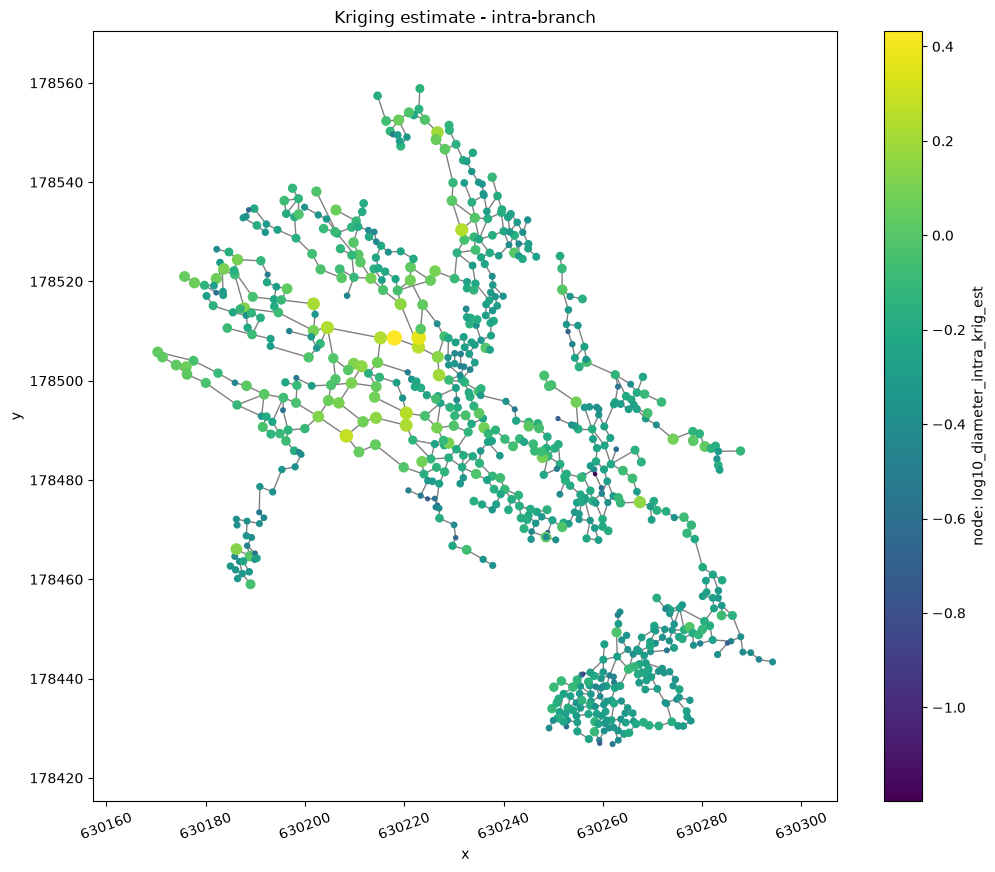

In [53]:
# Original graph
# --------------

# Attribute to be plotted
node_attr = node_attr_krig_est

# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 5
size_max = 100
size_nan = 1
exponent = 3
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options = {
    'node_size'   : node_size,  # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}

plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    G,
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title('Kriging estimate - intra-branch')
plt.axis('equal')
plt.show(block=True)


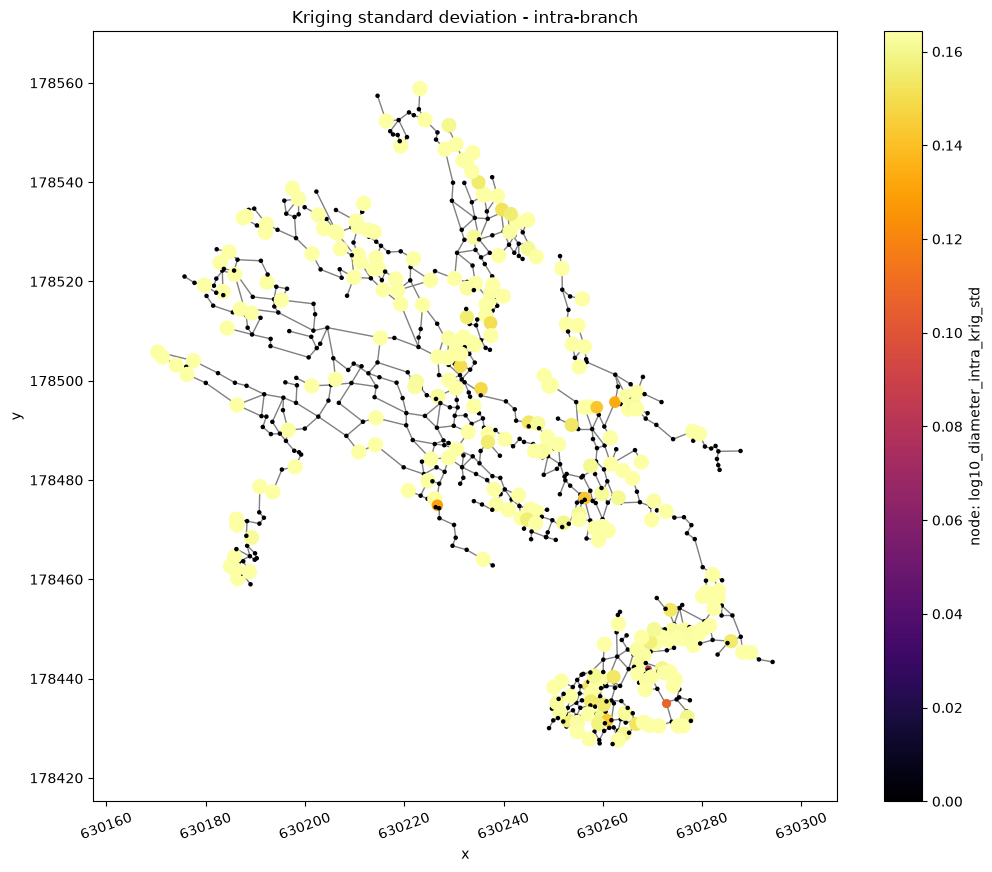

In [54]:
# Original graph
# --------------

# Attribute to be plotted
node_attr = node_attr_krig_std

# Color map for node attribute
cmap = plt.get_cmap('inferno')
# cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
# cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
# cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 5
size_max = 100
size_nan = 1
exponent = 3
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options = {
    'node_size'   : node_size,  # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}

plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    G,
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title('Kriging standard deviation - intra-branch')
plt.axis('equal')
plt.show(block=True)


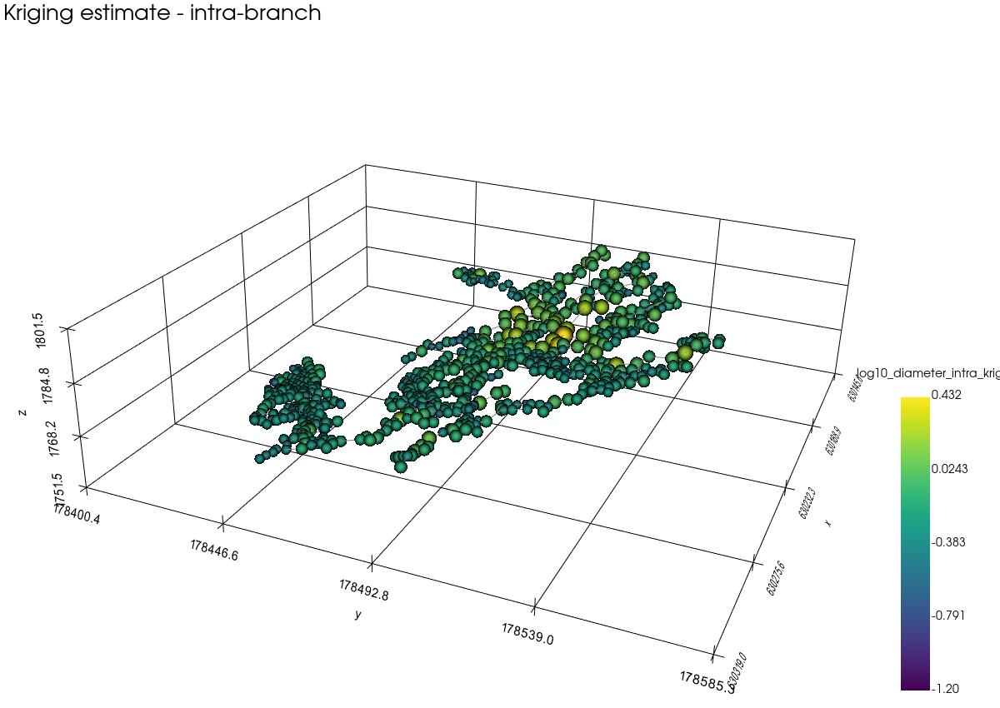

In [55]:
# Original graph
# --------------

# Attribute to be plotted
node_attr = node_attr_krig_est

# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold')       # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red', alpha=1.0) # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 1
size_max = 3
size_nan = 2
exponent = 2
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options_nodes = {
    'point_size' : node_size,  # node size
    'cmap'       : cmap,       # node color map
    #'vmin':-1.2
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=(1200, 850), notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':node_attr+'\n', 'title_font_size':14, 'label_font_size':14, 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text('Kriging estimate - intra-branch', font_size=12)

cpos = pp.show(cpos=cpos, return_cpos=True)


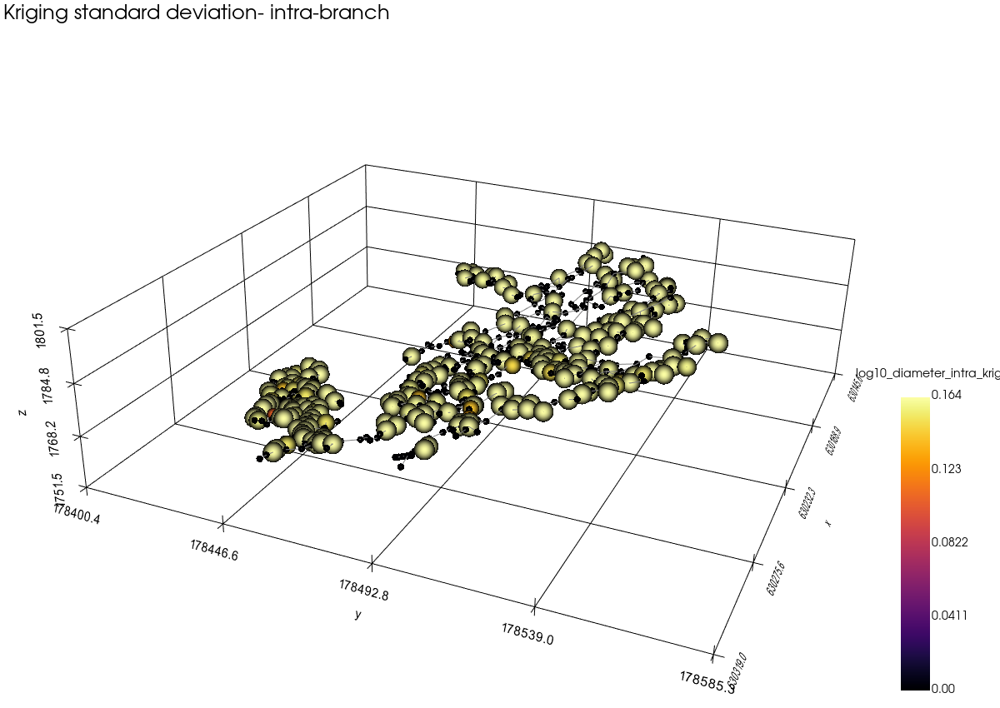

In [56]:
# Original graph
# --------------

# Attribute to be plotted
node_attr = node_attr_krig_std

# Color map for node attribute
cmap = plt.get_cmap('inferno')
# cmap.set_over('gold')       # color for value above upper limit 'vmax' (if specified)
# cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
# cmap.set_bad('red', alpha=1.0) # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 1
size_max = 3
size_nan = 2
exponent = 2
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options_nodes = {
    'point_size' : node_size,  # node size
    'cmap'       : cmap,       # node color map
    #'vmin':-1.2
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=(1200, 850), notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':node_attr+'\n', 'title_font_size':14, 'label_font_size':14, 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text('Kriging standard deviation- intra-branch', font_size=12)

cpos = pp.show(cpos=cpos, return_cpos=True)


### Sequential Gaussian Simulation (SGS)

The function `kn.tools.sgs_node_attribute[_mp]` do SGS on the nodes of a graph. 

The keyword argument `neighbors_on_same_branch_only=True` is used with the keyword argument `branches=kg.branches` to restrain the neighborhood to the current branch.

*Note: `kn.tools.sgs_node_attribute` is serial and `kn.tools.sgs_node_attribute_mp` use multiprocessing.*

In [57]:
# SGS - parallel

# Attribute to simulate
node_attr = 'log10_diameter'

# Parameters
# ----------
# Kriging type
# method = 'ordinary_kriging'
method = 'simple_kriging'
mean = 'log10_diameter_target_mean' # target mean (see step 4.1 above)

# Neighborhood parameters
use_unique_neighborhood = False # if True all nodes are taken into account for kriging (no neighborhood search)
nneighborMax = 12      # Maximal number of neighbors (if use_unique_neighborhood=False)
searchRadius = 200.0   # Maximal distance to search for neighbors (if use_unique_neighborhood=False)

nreal = 100  # number of realizations (SGS)
seed = 8724 # seed for reproducibility

# Node attributes for results of SGS
node_attr_sgs = node_attr + '_intra_sgs'

nproc = 4 # number of processes (multiprocessing)

t1 = time.time()
sgs = kn.tools.sgs_node_attribute_mp(
        G,         # Graph
        cov_model, # covariance model used (function)
        node_attr, # Node attribute to be kriged
        edge_length_attr='length', # Edge attribute used for distance computation
        method=method,
        mean=mean,
        neighbors_on_same_branch_only=True,
        branches=kg.branches,
        nneighborMax=nneighborMax,
        searchRadius=searchRadius,
        nreal=nreal,
        seed=seed,
        update_graph=True, # if True, add one new node attribute in the graph (array of SGS realizations)
        sgs_node_attr=node_attr_sgs,
        nproc=nproc,
        verbose=1)
t2 = time.time()
print(f'SGS {nreal} realizations ({nproc} processes) - Elapsed time: {t2-t1:.3g} sec')

Running `sgs_node_attr` on 4 processes...
[pid=0] SGS:   1% (  0 realizations done of 25)
[pid=0] SGS:   2% (  0 realizations done of 25)
[pid=0] SGS:   3% (  0 realizations done of 25)
[pid=0] SGS:   4% (  1 realizations done of 25)
[pid=0] SGS:   5% (  1 realizations done of 25)
[pid=0] SGS:   6% (  1 realizations done of 25)
[pid=0] SGS:   7% (  1 realizations done of 25)
[pid=0] SGS:   8% (  2 realizations done of 25)
[pid=0] SGS:   9% (  2 realizations done of 25)
[pid=0] SGS:  10% (  2 realizations done of 25)
[pid=0] SGS:  11% (  2 realizations done of 25)
[pid=0] SGS:  12% (  3 realizations done of 25)
[pid=0] SGS:  13% (  3 realizations done of 25)
[pid=0] SGS:  14% (  3 realizations done of 25)
[pid=0] SGS:  15% (  3 realizations done of 25)
[pid=0] SGS:  16% (  4 realizations done of 25)
[pid=0] SGS:  17% (  4 realizations done of 25)
[pid=0] SGS:  18% (  4 realizations done of 25)
[pid=0] SGS:  19% (  4 realizations done of 25)
[pid=0] SGS:  20% (  5 realizations done of 25

In [58]:
# Compute mean and std of simulations
node_attr_sgs_mean = node_attr_sgs + '_mean' 
node_attr_sgs_std = node_attr_sgs + '_std' 

sgs = nx.get_node_attributes(G, node_attr_sgs)

nsgs = len(sgs[list(G.nodes())[0]])

sgs_mean = {u:float(np.asarray(sgs[u]).mean()) for u in G.nodes()}
sgs_std = {u:float(np.asarray(sgs[u]).std()) for u in G.nodes()}

nx.set_node_attributes(G, sgs_mean, node_attr_sgs_mean)
nx.set_node_attributes(G, sgs_std, node_attr_sgs_std)


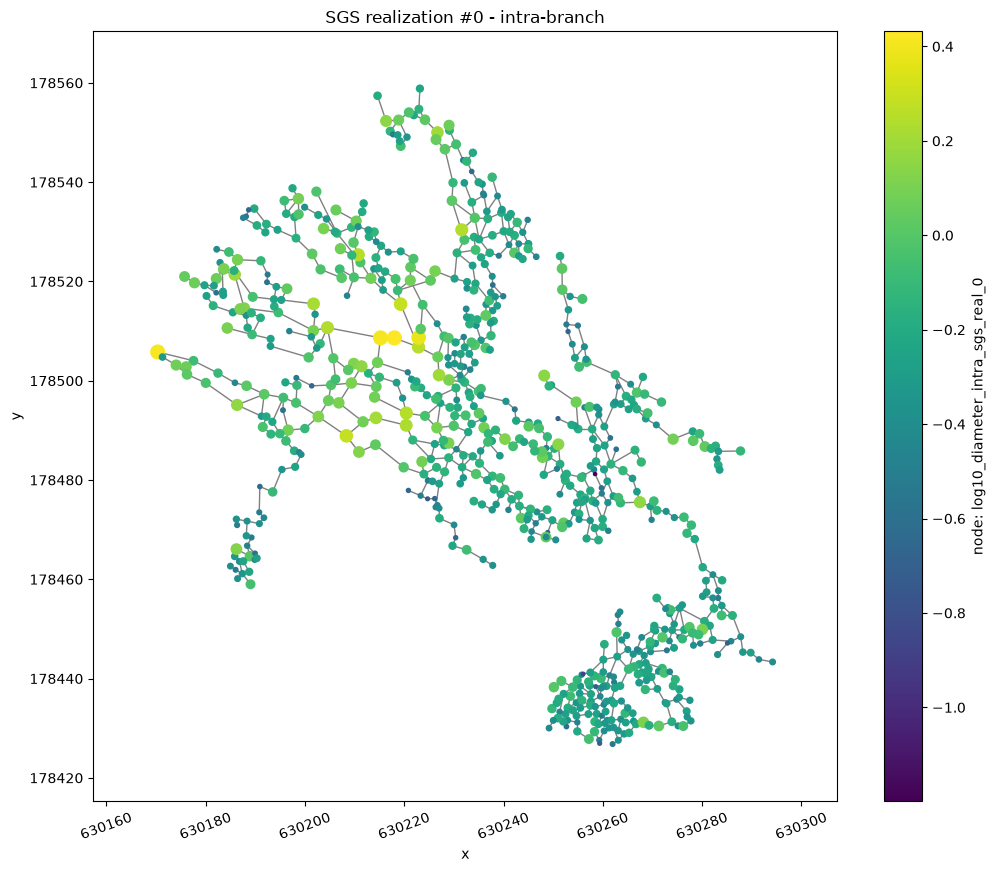

In [59]:
# Index of the realization to be plotted
index = 0

node_attr = f'{node_attr_sgs}_real_{index}' # temporary attribute: attribute to be plotted

sgs = nx.get_node_attributes(G, node_attr_sgs) # list of realization at each node
nx.set_node_attributes(G, {u:sgs[u][index] for u in G.nodes()}, node_attr) # Store the realization

# 2D plot
# -------
# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 5
size_max = 100
size_nan = 1
exponent = 3
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options = {
    'node_size'   : node_size,  # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}

plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    G,
    # node_attr='log10_diameter', # before simulation
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title(f'SGS realization #{index} - intra-branch')
plt.axis('equal')
plt.show()



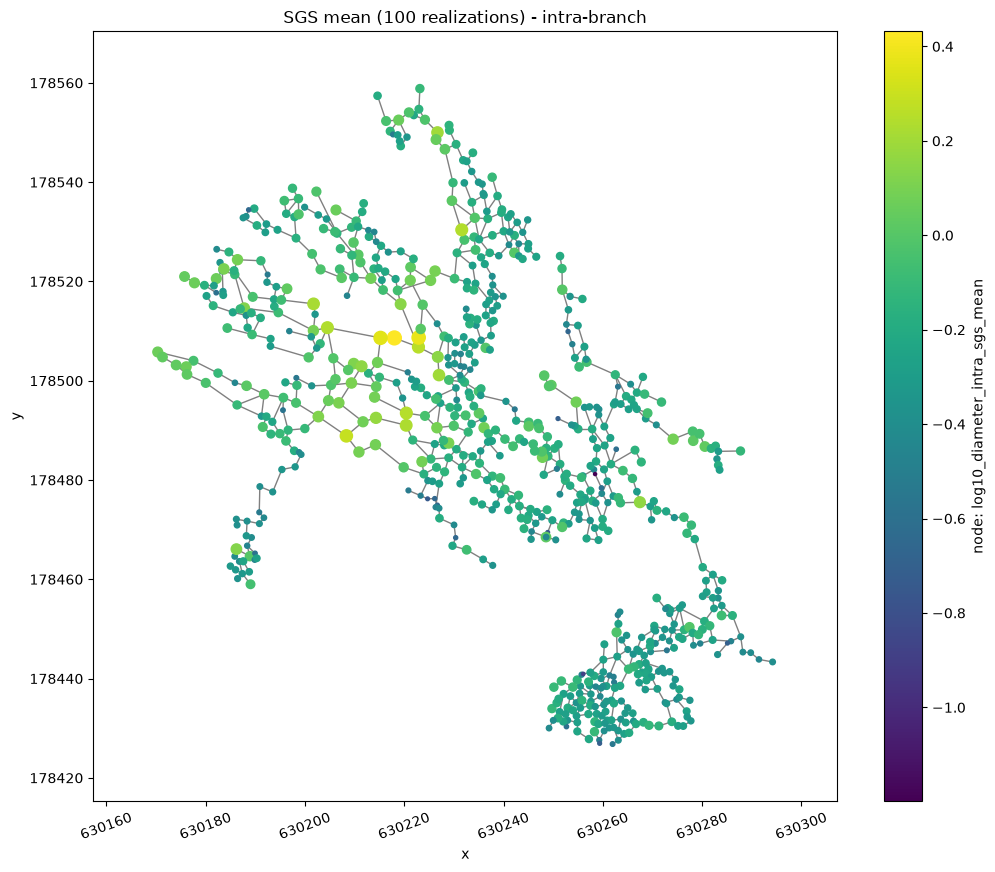

In [60]:
# Attribute to be plotted
node_attr = node_attr_sgs_mean

# 2D plot
# -------
# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 5
size_max = 100
size_nan = 1
exponent = 3
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options = {
    'node_size'   : node_size,  # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}

plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    G,
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title(f'SGS mean ({nsgs} realizations) - intra-branch')
plt.axis('equal')
plt.show()


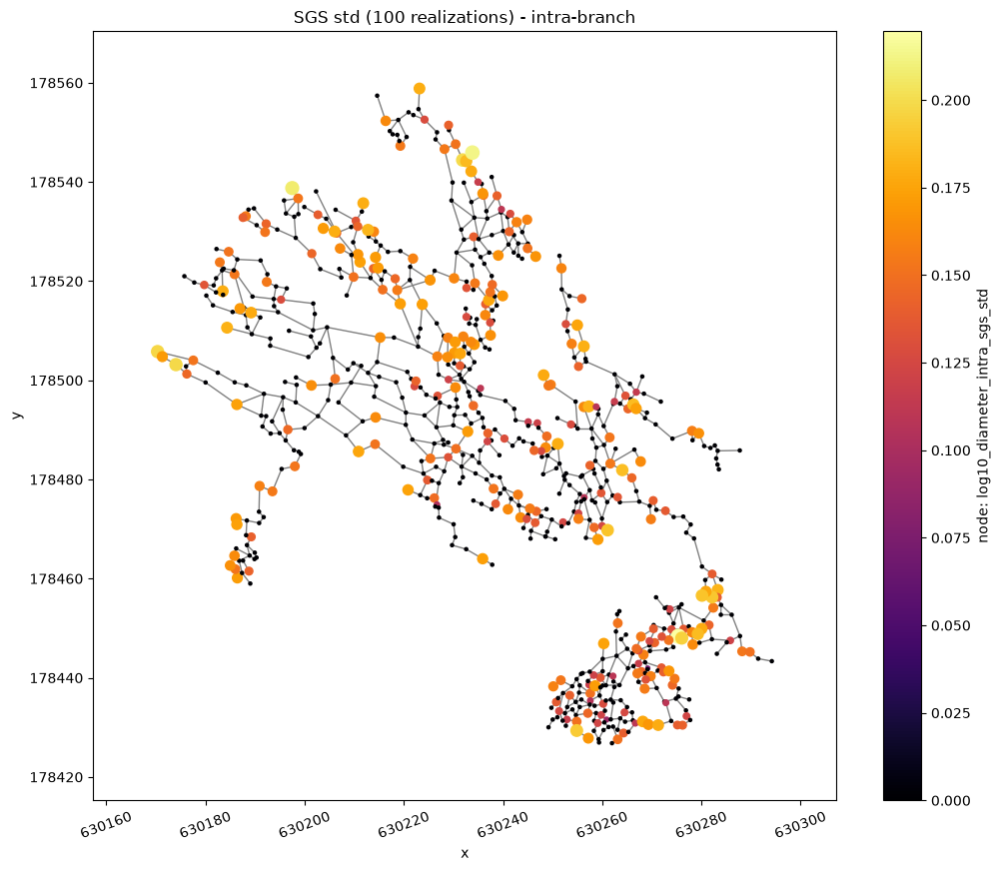

In [61]:
# Attribute to be plotted
node_attr = node_attr_sgs_std

# 2D plot
# -------
# Color map for node attribute
cmap = plt.get_cmap('inferno')
# cmap.set_over('gold') # color for value above upper limit 'vmax' (if specified)
# cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
# cmap.set_bad('red')         # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 5
size_max = 100
size_nan = 1
exponent = 3
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options = {
    'node_size'   : node_size,  # node size
    'cmap'        : cmap,       # node color map (for attribute values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',
    'with_labels' : False,       # show node labels ?
}


plt.figure(figsize=(12, 10))
kn.view.plot_graph2d(
    G,
    node_attr=node_attr,
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)
plt.title(f'SGS std ({nsgs} realizations) - intra-branch')
plt.axis('equal')
plt.show()


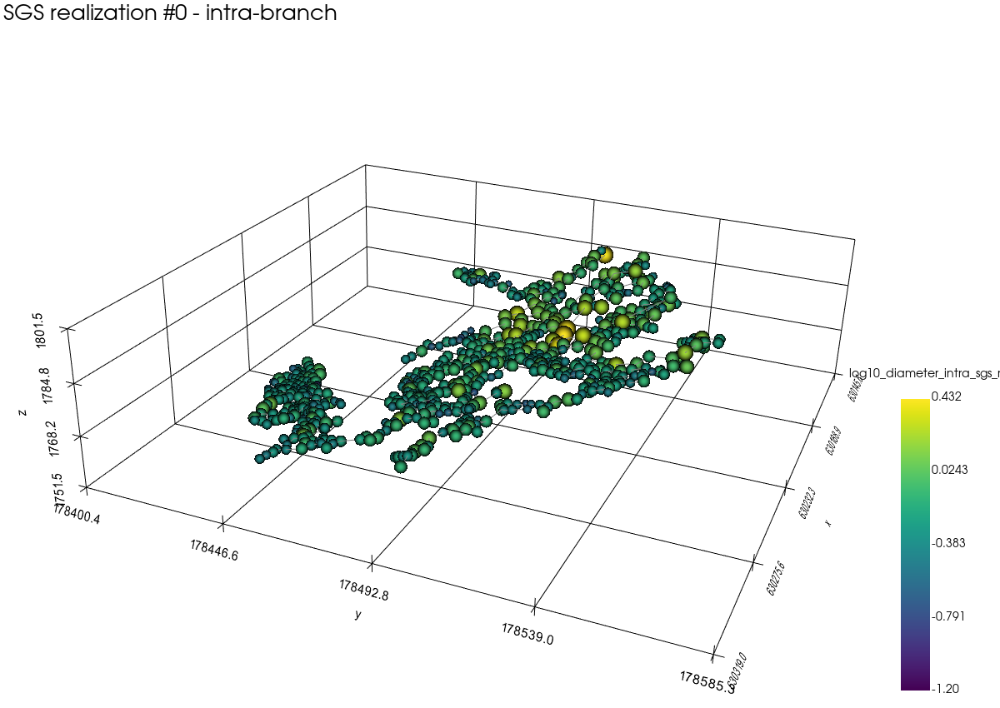

In [62]:
# Index of the realization to be plotted
index = 0

node_attr = f'{node_attr_sgs}_real_{index}' # temporary attribute: attribute to be plotted

sgs = nx.get_node_attributes(G, node_attr_sgs) # list of realization at each node
nx.set_node_attributes(G, {u:sgs[u][index] for u in G.nodes()}, node_attr) # Store the realization

# 3D plot
# -------
# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold')       # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red', alpha=1.0) # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 1
size_max = 3
size_nan = 2
exponent = 2
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options_nodes = {
    'point_size' : node_size,  # node size
    'cmap'       : cmap,       # node color map
    #'vmin':-1.2
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=None, notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':node_attr+'\n', 'title_font_size':14, 'label_font_size':14, 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text(f'SGS realization #{index} - intra-branch', font_size=12)
pp.scalar_bar.GetTitleTextProperty().SetLineSpacing(1.2) # to add space between scalar bar title and scalar bar (with '\n' in title)

pp.show(cpos=cpos)



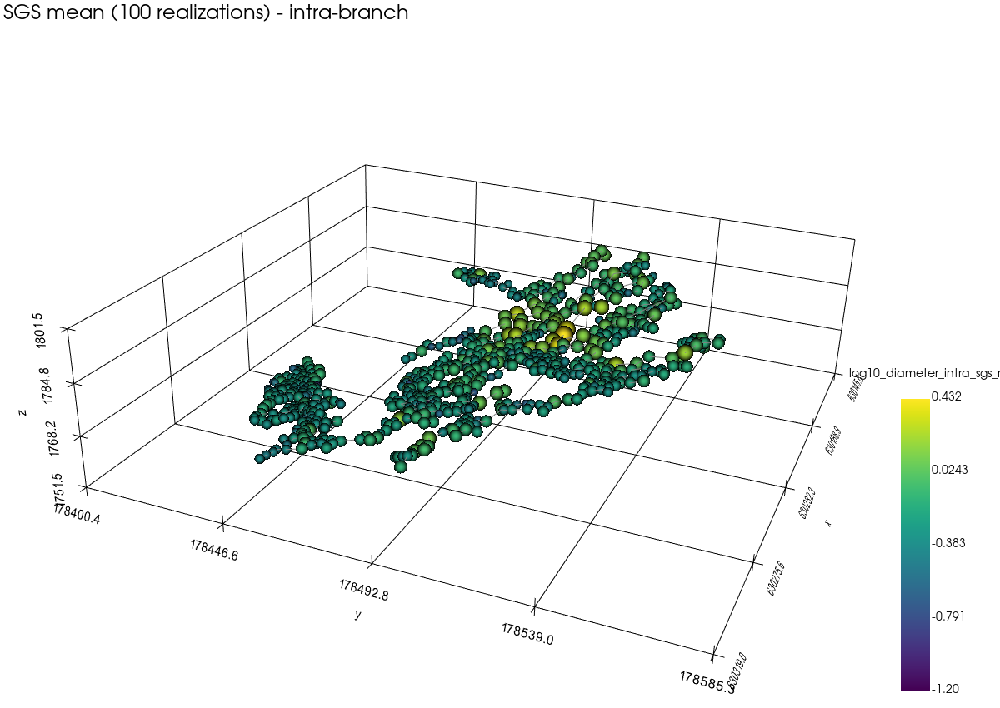

In [63]:
# Attribute to be plotted
node_attr = node_attr_sgs_mean

# 3D plot
# -------
# Color map for node attribute
cmap = plt.get_cmap('viridis')
cmap.set_over('gold')       # color for value above upper limit 'vmax' (if specified)
cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
cmap.set_bad('red', alpha=1.0) # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 1
size_max = 3
size_nan = 2
exponent = 2
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options_nodes = {
    'point_size' : node_size,  # node size
    'cmap'       : cmap,       # node color map
    #'vmin':-1.2
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=None, notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':node_attr+'\n', 'title_font_size':14, 'label_font_size':14, 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text(f'SGS mean ({nsgs} realizations) - intra-branch', font_size=12)
pp.scalar_bar.GetTitleTextProperty().SetLineSpacing(1.2) # to add space between scalar bar title and scalar bar (with '\n' in title)

pp.show(cpos=cpos)



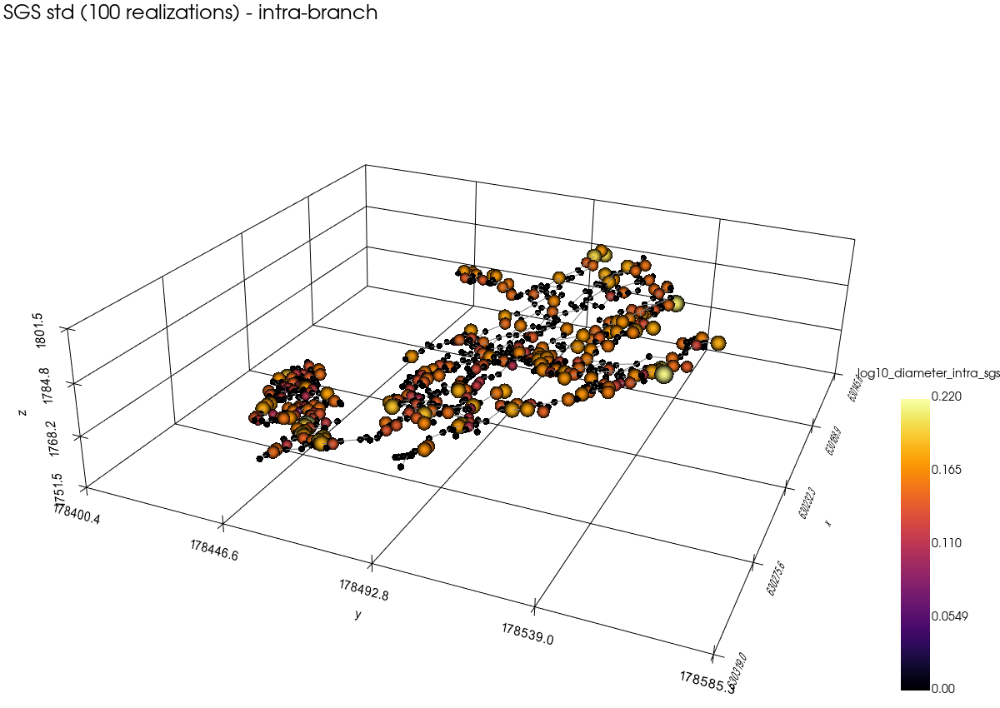

In [64]:
# Attribute to be plotted
node_attr = node_attr_sgs_std

# 3D plot
# -------
# Color map for node attribute
cmap = plt.get_cmap('inferno')
# cmap.set_over('gold')       # color for value above upper limit 'vmax' (if specified)
# cmap.set_under('cyan')      # color for value below lower limit 'vmin' (if specified)
# cmap.set_bad('red', alpha=1.0) # color for nan value (missing data) / will be overwritten by 'node_color' (if specified)

# Set custom node size according to the node property
size_min = 1
size_max = 3
size_nan = 2
exponent = 2
a = nx.get_node_attributes(G, node_attr, default=np.nan)
node_size = kn.utils.rescale_array(np.asarray(list(a.values())), size_min, size_max, exponent=exponent, nan_val=size_nan, in_min=None, in_max=None)

options_nodes = {
    'point_size' : node_size,  # node size
    'cmap'       : cmap,       # node color map
    #'vmin':-1.2
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=None, notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':node_attr+'\n', 'title_font_size':14, 'label_font_size':14, 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text(f'SGS std ({nsgs} realizations) - intra-branch', font_size=12)
pp.scalar_bar.GetTitleTextProperty().SetLineSpacing(1.2) # to add space between scalar bar title and scalar bar (with '\n' in title)

pp.show(cpos=cpos)



### Compare results
- kriging estimates and initial values (before removing)
- mean of simulations and kriging estimates
- standard deviation of simulations and kriging standard deviation

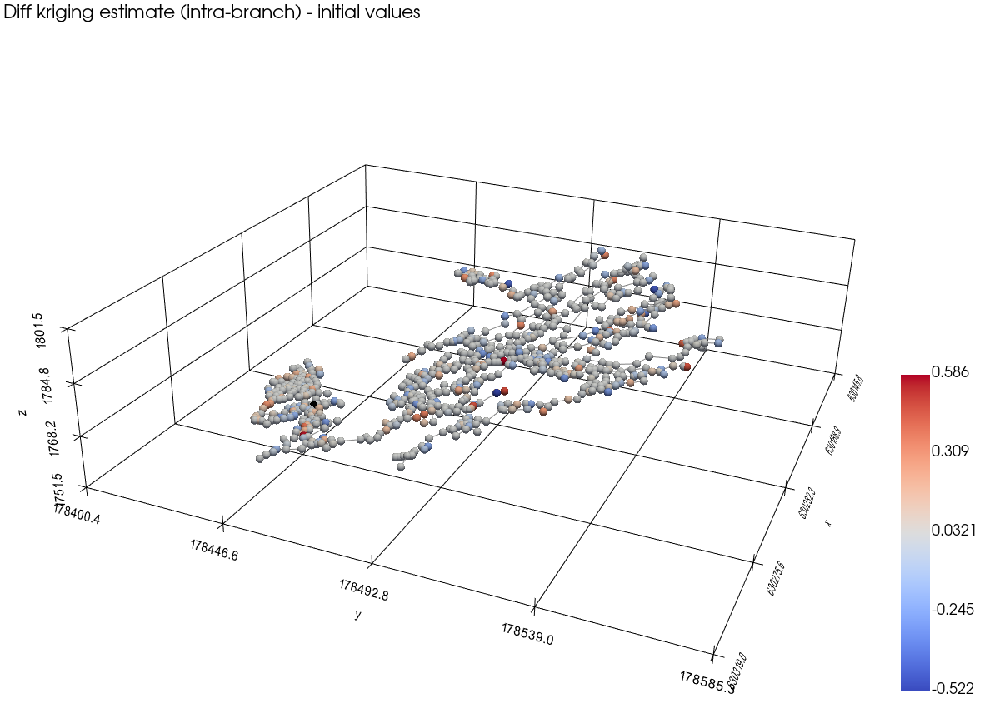

In [65]:
# Difference between SGS mean and initial values
# ------------------------------------------------
d1 = nx.get_node_attributes(G, node_attr_krig_est)
d2 = node_attr_dict_save
nx.set_node_attributes(G, {u:d1[u]-d2[u] for u in G.nodes()}, '_tmp_') # Store the realization as '_tmp_' (temporary attribute)
node_attr = '_tmp_'

# 3D plot
# -------
options_nodes = {
    'point_size' : 10,         # node size
    'cmap'       : 'coolwarm', # node color map
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=None, notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':'', 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text(f'Diff kriging estimate (intra-branch) - initial values', font_size=12)
pp.scalar_bar.GetTitleTextProperty().SetLineSpacing(1.2) # to add space between scalar bar title and scalar bar (with '\n' in title)

pp.show(cpos=cpos)



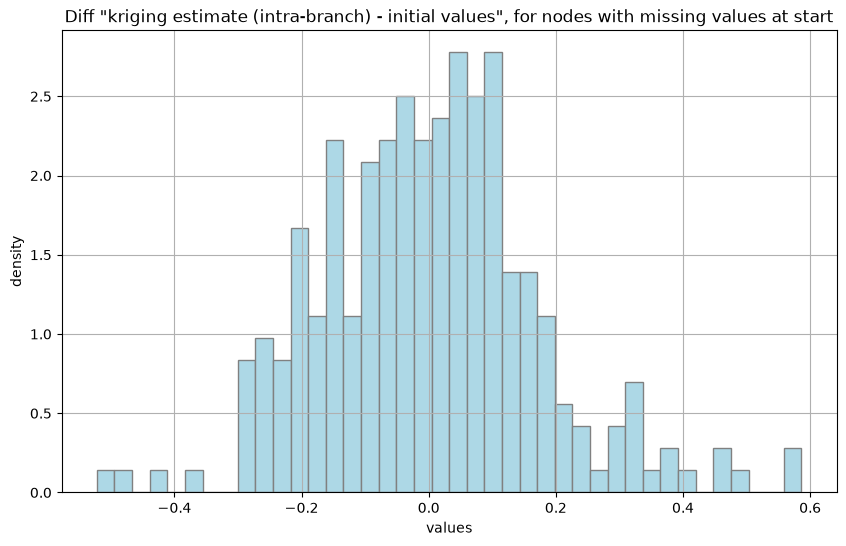

In [66]:
# Histogram
plt.figure(figsize=(10, 6))
plt.hist(np.asarray([d1[u] - d2[u] for u in nodes_with_missing_values]), density=True, bins=40, color='lightblue', edgecolor='gray')
plt.xlabel('values')
plt.ylabel('density')
plt.title('Diff "kriging estimate (intra-branch) - initial values", for nodes with missing values at start')
plt.grid()
plt.show()

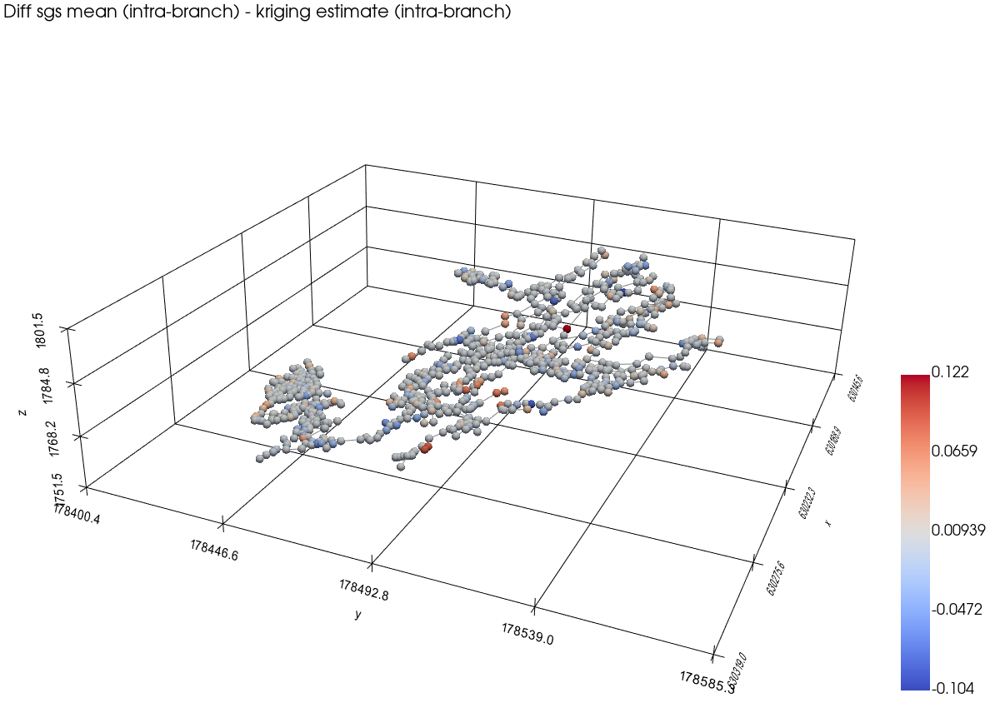

In [67]:
# Difference between SGS mean and Kriging estimate
# ------------------------------------------------
d1 = nx.get_node_attributes(G, node_attr_sgs_mean)
d2 = nx.get_node_attributes(G, node_attr_krig_est)
nx.set_node_attributes(G, {u:d1[u]-d2[u] for u in G.nodes()}, '_tmp_') # Store the realization as '_tmp_' (temporary attribute)
node_attr = '_tmp_'

# 3D plot
# -------
options_nodes = {
    'point_size' : 10,         # node size
    'cmap'       : 'coolwarm', # node color map
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

# cpos = None
cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=None, notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':'', 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text(f'Diff sgs mean (intra-branch) - kriging estimate (intra-branch)', font_size=12)
pp.scalar_bar.GetTitleTextProperty().SetLineSpacing(1.2) # to add space between scalar bar title and scalar bar (with '\n' in title)

pp.show(cpos=cpos)



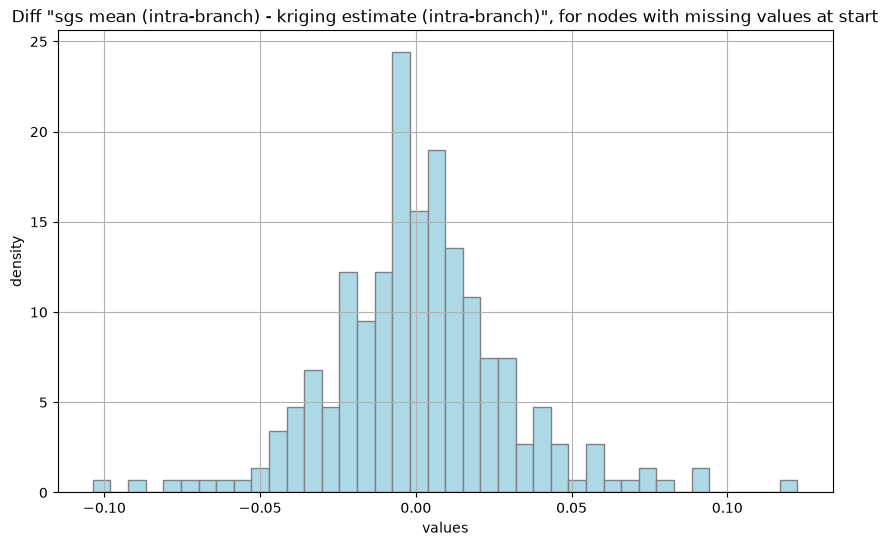

In [68]:
# Histogram
plt.figure(figsize=(10, 6))
plt.hist(np.asarray([d1[u] - d2[u] for u in nodes_with_missing_values]), density=True, bins=40, color='lightblue', edgecolor='gray')
plt.xlabel('values')
plt.ylabel('density')
plt.title('Diff "sgs mean (intra-branch) - kriging estimate (intra-branch)", for nodes with missing values at start')
plt.grid()
plt.show()

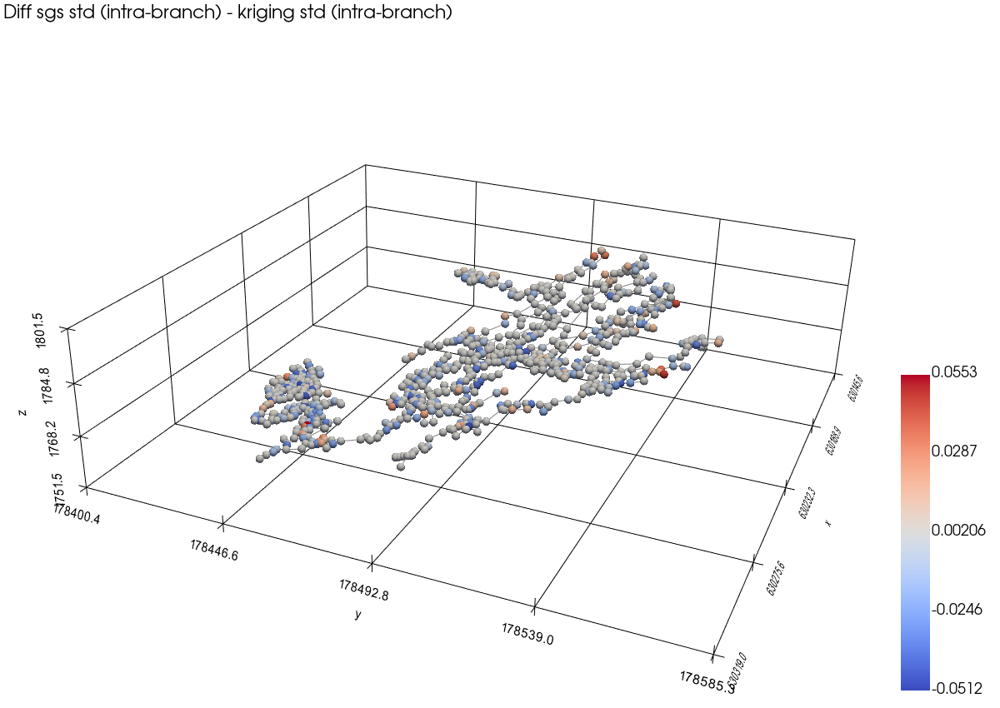

In [69]:
# Difference between SGS std and Kriging std
# ------------------------------------------
d1 = nx.get_node_attributes(G, node_attr_sgs_std)
d2 = nx.get_node_attributes(G, node_attr_krig_std)
nx.set_node_attributes(G, {u:d1[u]-d2[u] for u in G.nodes()}, '_tmp_') # Store the realization as '_tmp_' (temporary attribute)
node_attr = '_tmp_'

# 3D plot
# -------
options_nodes = {
    'point_size' : 10,         # node size
    'cmap'       : 'coolwarm', # node color map
}

options_edges = {
    'line_width' : 1,         # edge line width
    'color'      : 'gray',    # edge color
}

cpos = [
    (630579.9564230355, 178631.67095510167, 1949.5761769908295),
    (630232.27, 178492.83000000002, 1776.4850000000001),
    (-0.378194097774041, -0.18399021865942627, 0.9072578596223545)
]

# pp = pv.Plotter(window_size=None, notebook=False) # plot in a pop-up window
pp = pv.Plotter(window_size=(1200, 850))
kn.view.pv_plot_graph(
    G, 
    plotter=pp,
    node_attr=node_attr,
    options_nodes=options_nodes,
    options_edges=options_edges,
    options_node_colorbar={'title':'', 'vertical':True},
    show_grid=True,
    options_show_grid={'font_size':12, 'padding':0.2},
    # show_outline=True,
    # options_show_outline={'line_width':2, 'color':'darkgreen'},
    with_labels=False
)
pp.add_text(f'Diff sgs std (intra-branch) - kriging std (intra-branch)', font_size=12)
pp.scalar_bar.GetTitleTextProperty().SetLineSpacing(1.2) # to add space between scalar bar title and scalar bar (with '\n' in title)

pp.show(cpos=cpos)



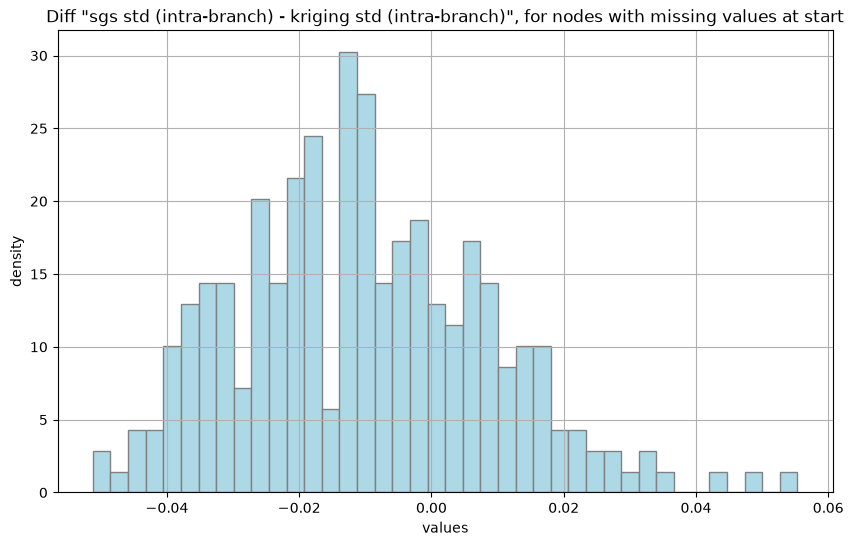

In [70]:
# Histogram
plt.figure(figsize=(10, 6))
plt.hist(np.asarray([d1[u] - d2[u] for u in nodes_with_missing_values]), density=True, bins=40, color='lightblue', edgecolor='gray')
plt.xlabel('values')
plt.ylabel('density')
plt.title('Diff "sgs std (intra-branch) - kriging std (intra-branch)", for nodes with missing values at start')
plt.grid()
plt.show()